# Session 5 · From theory to computational simulation
## Classical and agent-based predator–prey models
**Theory → classical implementation → W1 + S1 → W1 + S2 + P1 → W2 + S3 → experimental design**

This notebook is lecture material and a student laboratory. The aim is to read, run, question, and make small changes to models—not to become a programmer in one session.

**Learning outcomes:** distinguish an empirical pattern from a theory; connect Four As/LUL ontology to a clocked process and executable code; explain how local rules produce aggregate behavior; design repeated computational experiments.

**Suggested 180 minutes:** theory 20; classical model 30; Take 1 30; grass 35; occupancy 30; comparison and BehaviorSpace 25; reflection 10.

### Run instructions
Use JupyterLab/Notebook with Python 3.9+ or upload this file to Google Colab. Run cells in order. Python computes Lotka–Volterra only. **The ABMs are actual NetLogo models, executed separately in NetLogo Web or desktop.** The notebook exports their complete files; no Python surrogate is used. Internet is needed for installation and NetLogo Web. Static plots and diagrams remain visible without widgets.

If imports fail, uncomment and run the installation cell, then restart the kernel and run all. Trust the notebook only after reviewing it. Do not run the full 2,430-run experiment during class. CSV analysis is reserved for **after Homework 2**.

### Evidence labels
- **Empirical:** the paper’s historical lynx–hare figure; no raw historical series is supplied here.
- **Computed:** SciPy outputs generated by Python cells; NetLogo outputs only when the model is run.
- **Paper-reported / expected:** qualitative findings from the paper, not promises about these defaults.
- **Implementation choice:** details needed to turn published summaries into runnable models.


In [1]:
# Uncomment only if needed:
# %pip install numpy scipy matplotlib ipywidgets


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display, HTML, Markdown, IFrame, FileLink
from pathlib import Path
import base64, zlib, xml.etree.ElementTree as ET
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Python ready. NetLogo models run in NetLogo Web or desktop, separately.')

Python ready. NetLogo models run in NetLogo Web or desktop, separately.


## 1 · Pattern, question, theory
The uploaded Wilensky–Reisman manuscript introduces fluctuations in northern Canadian hare and lynx records (Figure 1, graph on manuscript p. 11, caption p. 12). These are **pelt records**, as the axis says; harvesting, reporting, and other ecological mechanisms can affect them. They are not a controlled test of predation alone.

**Phenomenon:** population proxies fluctuate and predator peaks often follow prey peaks. **Question:** which interaction mechanisms can generate such behavior, and under what conditions do they permit coexistence?

**Proposed explanation:** more prey creates feeding opportunities for predators; more predators increase prey mortality; diminished prey lowers predator survival or recruitment; fewer predators permit prey recovery. Resource availability and spatial constraints may alter this feedback. A pattern is what we seek to explain; the theory proposes the mechanism.

The image below reproduces the supplied paper’s Figure 1 for this teaching discussion, credited there to Purves, Orians & Heller (1992). It is not digitized or fitted in this notebook. Wolves and sheep are generic modeling roles, not a claim that the historical observations concern those species.

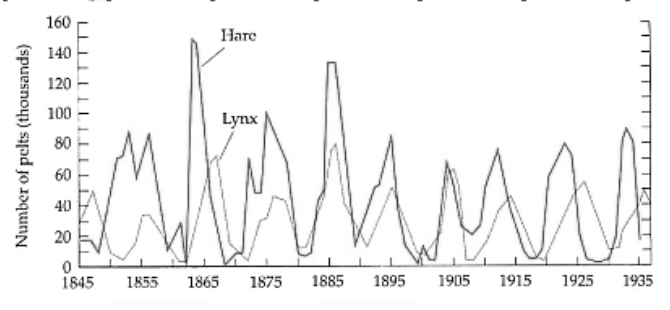

**Exercise 1:** Mark one observable pattern, one mechanism, and one competing explanation. What additional observation would discriminate the explanations?

## 2 · Classical implementation: Lotka–Volterra
The paper’s equations (manuscript pp. 12–13) are

$$
\frac{dN_1}{dt}=b_1N_1-k_1N_1N_2,\qquad
\frac{dN_2}{dt}=k_2N_1N_2-d_2N_2.
$$

Here $N_1$ is prey and $N_2$ predator abundance (or density with consistent coefficients). Prey growth is independent of resources; encounters scale with the product of the two populations; predator recruitment depends on prey encounters; predator mortality is proportional to predator abundance. Mixing is implicit; individuals and local space are absent.

The positive equilibrium is $N_1^*=d_2/k_2$, $N_2^*=b_1/k_1$. With positive parameters and positive starting populations, the ideal system has closed orbits around that equilibrium; these are neutrally stable, not attracting cycles. A positive continuous trajectory does not hit an integer extinction threshold.

**All values below are illustrative**, not estimates from the pelt record or a reproduction of Figure 2. The paper’s Figure 2 starts with 50,000 hares and 1,250 lynx; we use a smaller scale for readability. ODE rate coefficients are not NetLogo per-tick reproduction percentages.


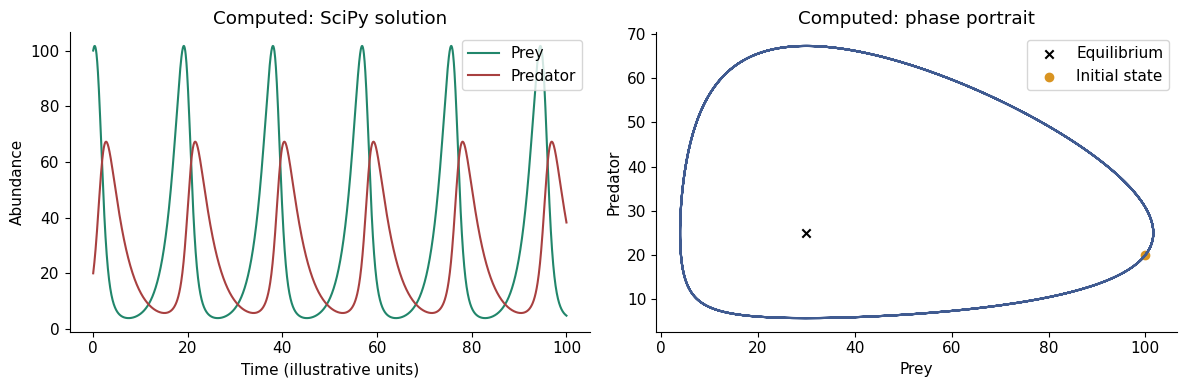

Conserved-quantity numerical drift: 7.47e-09


In [2]:
def lv_rhs(t, y, b1, k1, k2, d2):
    prey, predator = y
    return [b1 * prey - k1 * prey * predator,
            k2 * prey * predator - d2 * predator]

def solve_lv(b1=.5, k1=.02, k2=.01, d2=.3, prey0=100., predator0=20., duration=100.):
    sol = solve_ivp(lv_rhs, (0, duration), [prey0, predator0],
                   args=(b1, k1, k2, d2), t_eval=np.linspace(0, duration, 2001),
                   rtol=1e-9, atol=1e-11)
    if not sol.success:
        raise RuntimeError(sol.message)
    if not np.all(np.isfinite(sol.y)) or np.any(sol.y <= 0):
        raise RuntimeError('Nonpositive or invalid numerical result; check parameters/tolerance.')
    return sol

def plot_lv(b1=.5, k1=.02, k2=.01, d2=.3, prey0=100., predator0=20., duration=100.):
    sol = solve_lv(b1, k1, k2, d2, prey0, predator0, duration)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(sol.t, sol.y[0], label='Prey', color='#21866b')
    ax[0].plot(sol.t, sol.y[1], label='Predator', color='#a84040')
    ax[0].set(xlabel='Time (illustrative units)', ylabel='Abundance', title='Computed: SciPy solution')
    ax[0].legend()
    ax[1].plot(sol.y[0], sol.y[1], color='#405b91')
    ax[1].scatter([d2/k2], [b1/k1], marker='x', color='black', label='Equilibrium')
    ax[1].scatter([prey0], [predator0], color='#d99421', label='Initial state')
    ax[1].set(xlabel='Prey', ylabel='Predator', title='Computed: phase portrait')
    ax[1].legend(); plt.tight_layout(); plt.show()
    return sol

baseline = plot_lv()
# The exact equations conserve this quantity along a positive trajectory.
x, y = baseline.y
H = .01*x - .3*np.log(x) + .02*y - .5*np.log(y)
print(f'Conserved-quantity numerical drift: {np.ptp(H):.3g}')
assert np.ptp(H) < 1e-5, 'Numerical precision check failed.' 

In [3]:
# Widgets need a widget-capable notebook front end. Static baseline above always works.
try:
    import ipywidgets as widgets
    controls = {
        'b1': widgets.FloatSlider(value=.5, min=.1, max=1., step=.05, description='Prey birth'),
        'k1': widgets.FloatSlider(value=.02, min=.005, max=.04, step=.005, readout_format='.3f', description='Predation'),
        'k2': widgets.FloatSlider(value=.01, min=.005, max=.03, step=.005, readout_format='.3f', description='Recruitment'),
        'd2': widgets.FloatSlider(value=.3, min=.1, max=.8, step=.05, description='Predator death'),
        'prey0': widgets.IntSlider(value=100, min=10, max=150, step=10, description='Initial prey'),
        'predator0': widgets.IntSlider(value=20, min=5, max=60, step=5, description='Initial predator')}
    panel = widgets.interactive_output(lambda **kw: plot_lv(**kw), controls)
    display(widgets.VBox(list(controls.values())), panel)
except ImportError:
    print('Widgets unavailable. Change arguments in plot_lv(...) below and rerun.')
# Example without widgets: plot_lv(b1=.6, predator0=30)


Output()

**Exercise 2:** Predict how changing predator mortality shifts the positive equilibrium before touching the controls. Then compare trajectories. Start exactly at `(d2/k2, b1/k1)`: why is the curve flat? Why would rounding each solution point to an integer not turn this into an ABM?

## 3 · From ontology to a working process
We use Homework 2’s exact Four As: **A1 Agent; A2 Arena; A3 Artificiality (material A3m or social A3s); A4 Array**, the meaningful configuration and connections. A4 is not another class. **LUL = Light-UML-Like**: class → states → methods → connections. A connection enables access/influence; it is not a temporal arrow.

Each take below shows four progressive LUL drafts. The first two agent classes are Wolf and Sheep. The Arena is the patch world. Grass is represented as an **A3m resource layer** stored in patch states, not an independent decision-making turtle. This is a modeling-role choice: another ontology might include it within Arena. No A3s class is needed. Observer scheduling, measurement, and the clock are implementation services, not biological agents.

**NetLogo bridge:** breeds implement agent classes; `turtles-own` stores individual states; `patches-own` stores local resource states; `ask` invokes actions; `one-of` selects locally; `hatch` creates offspring; `die` removes an individual; `tick` advances the clock; `report` returns a measured quantity. There are no NetLogo links in these models: A4 connections are implemented through queries such as `sheep-here` and `neighbors`.

### Common conventions (implementation choices)
Eight-neighbor adjacent-patch movement on a wrapping 51 × 51 world; animals sit at patch centers. Each tick runs sheep in random order, then wolves in random order, then grass regrowth. Breed `ask` uses the agents present when that call begins: offspring do not take another same-breed turn during that call. Sheep newborns can be eaten in the subsequent wolf phase. Thus the schedule matters.

Food gains are 4 for sheep and 20 for wolves, energy cost 1, initial energies random integers below those gains, and half the patches initially have grass. Reproduction divides energetic animals’ energy between parent and offspring; non-energetic sheep have no meaningful energy state. These energy/placement details follow the teaching-model style and are not specified by the paper’s summaries. One tick has no calibrated duration.

The notebook models reset the random generator to 2026 in `setup`; use `setup` then `random-seed 2027` for a different trajectory. For classroom control, stop after 1,500 ticks, no animals, or a 20,000-animal safety cap. The cap is a computational limit, not an ecological carrying capacity; label cap-limited runs as censored. Predator extinction alone does not stop Take 1, so prey proliferation can be observed.


In [5]:
# Export complete models (code, interface, shapes, documentation, smoke experiment).
MODEL_BLOBS = {'session5_take1.nlogox': 'eJztPWtz4zaS3/0rsNq61MxdZPMlUsrYTuUmU3u5y6vi2UtSU1MpWoJkrilSISnb2l9/DRDgQ2KjKVnyzF3dfBlLBBv9Qj8B6HKZznjMHniWR2lyNfiRF9+ni5QF59a5O2B5Eq7ep3/LotnVoMjWfHB9xtjlFN65fsNueC5eYiNW8HB6FyULlvFpmuQwclqIJ+mc/RrFPMnvN+yLcLl6w37hUb4ME5atY87y9XIZZhHPz8/esO+Wq5gveVKE8tXpXRpNec7CjLNZOl2LJ3zGooQVd5wlacFv0/T+/GwRp7dhnLMPrAjv+TBZL295xvI7zlfDRRglw3mWLofzNJ2xxzSeb30H1Oh/y/SBD6dpXrCc89nwIYzXnC3Dp2ERTe9ztkpX61iiNpyGK5YX6WqY8TAHVD+e3WbwCqAgp2XhsPy//h5mfgBaBALwbbHOipjnw/QxgWc84dliA1+vwmJ6V309TddJMRN/fzw7K1JAqlivAN1pzMNsGMYx/A3ftai21XcNAhzL8eHbLExmQLJ40Hiqh3cxy1MPO5gGQNXDmmd66pph9sjSw7Z451hW9ajJx0G2ThLQogE8C/N7phgi+CqATNM4zdhtJngivqg5ZAGPGIvmLWZcMYd9kPIVsJIh6OKreZwCiFfyzQr8BXNev+6ebAHySyTwNkaPUXHHPqhBVyVOH9VsbAu5kvXsFXCGvYojwSuAG+Y5kL2AF4s7YNiSv34t3xZzdRLjKvDwIEqiIgpj9Uwp2xeL4g1rEwa4bQ1VetgxVuPOswxeG7yD9axfZvmKT2GRsuUakJ9HBTwAhRTLUL4NKpLFs/NBC/8pyLTgCrdOhMsZS/0LV5wN5NcDxT3B2Me7qODliOifXKpY+YJaMoqzXeqrWMXjnG/zURH6oVReICRNuFCOtmzBwLAw2XytoN/xjH9UimB4d4t6xe5uIezQL1Zak/zbOJzeN8g/dxEGYHbtKPSX2O7LgIwDmqUhOOPJTFqwRar0WpoHoYNXDXPxYdcciGXB4mgZFQP5QC+MCjdlSLveTVIYEi3BM7TfLbVev1gisWWeOqDVI1geznmxYTCwAfiNtA7rXPgrLZU0mwHDBTfBZwn/yKQ3eKOdxLRgt3yegnsrWXyurJ5aHUrx8oKXU4hHWnNKiVePugzflgEVhmYorQ4rpSiYXkmmnurMqDUfWCw9TraA/5TkEx4t7m7TzLRwlNZIPOW7f7kCId6ms01Dk9QjrWQ7KlZPZDT2jeWh/hvWbkpb0Mpylwa+abibbqbTnnfY7sa49tT/hhunjxoXNfSLGGyyBWTPIt70Aspzg+cKwXNYVjmwBJvxVZbO1lNe+Qbjgt9DeDpEaYoPE+CddAJ2pygbFqNTS3dZBt6Y1TPuwt7VBsUtrczV2jiiLjeN4AmU+Q17VxIvdBRMyGoVAz8eQDNhlhC8Sfo442X8CoYnEWgJeOzVrw6TVsB5fX5Gq74geJXxjUaiXqGlqslnTWqkDRFfKq3s1PCuAFHpLqbaqFpLWKfT6g4xIoJs5AWdKtp4jqt/Nai5DMzgDtD32rSftW1bGSnXVrE2YfVfQxVVac8ovxSiuJIC6wyFq6mFpNKsYDHI8g/B6j8aaDTF9ZdysavhlooQ5Ach+n/dikW3oms580dgU2vUNhLpdLpehcl0M0zvv67hV7JvAy9B1QugDIltETKXjxqqop6VZF9eyORXZMGP0QzEnF9LBl4+RPyRPV0NPNsfsMcM1jBkMt/EcfrIZ7+p5Jltrga2NWDzLFzyXyBCvBq41jl8sYySnzfTNLsaDJ3RgN0JYRdXg1EwgSDjLn18D976rcCLZxqUpOcGAkMAaZ87Abw2T5NCfePt4PC7fhHQLu4U7KKG+314y2MYI4KxgYjLFEICn/VqBsj+AIQD6PLhU/VQ4P5U436h+LGKgfPADxe+C9dF+jN8rvnwQ/gkWCGJ108rDDffPEX5lQi6ziXL3AnAePohSq4G8gXNHnviDGD5L0Au+tWnJuBN/cpTCVI46wGYoXwVh5urRliXV3xxPRguAu7/1iURa3Ct1uelTMI1ifC5ZEzji5Ww2YKdkF8DHlK2km1WY1qV6Ej9Bq75thN4ky1KriuTsD1pNe21ZHFDky8v1AONzQWgsx9qpdrXuNm+500sx30ediXUI6An7UsDu5ELuFkHY7dluAwIwp/wgvp7mUJCB5biSSwAUE1wkdOo1BWnVFinoaW+1VqZdoOcrfkrHbTtYFcHd5BVaOwi5XktnNy9cFLKqTGxOlZDS+VQLGyh0wejoRWRxkMrVxuRPI5E+iVEZI8GMkpSWgXAHbHGl8pStCdthB8NO1yaaGVLZhEQVUgk/iPNon8CAWEMX/N5uI7F6AF7CLMovI35Lsg1IAmG6F9qyvzRDmWVEa2pcIO+RGylBh1U2H2o8JpU7MDcJSPwcDJEtbZcLQp14QRvw+k9xC7rZPZtmN3L8W1dqBaDK+jM7kVscjWYQ0rfIMoegxfjT8VbYRJKQEO78dX35TAwZEEQOMI31/OqZ6BJv4rIGmxFAf4SVEngu4W6rzEf7YF5KaGTYn4jqwWdqNfKY1t2pT2SDOH7peq41o55bae2XepDK49rNbWnE6zikWM7vdTfahPgOLXuNynoqjR2rWOaBLmoahq6AfdR/qYlOowKbQuPT8a2lTXZott1UaRJRYcIZb1GrOqVBIhp/p4UUSxC1lyHZaLM9VDHrveR8NU/3ebg7XnWVMC0wiXYReV6kV5elGjs4GSLOLMnTmohVkipzyhWMoioEPMnu4jJEU3cLi8a2cFllMzT67/+ld28u7n57qcf2Yi9/+a/3kHq9b67b/ZG9GhYOJ2mS0hpNmKAbngJrCH2X4FGLcv4HtKbGYs6m2fnZzfdtcY3Mr0U41mUszLLFM06yTcWzv4RTnmdar0pK/wyoxAwZUwli52ynyRaTOfsfQqzhsmCl1+G80K04cTQr1rdJxgdnJ99W+pnzqI4XgPdIopecgEgypf5lzJtm0eF6PjdRTm49Wgaxo1CrUCjSAG06DKVFWXxkq75fikSOcf6EpaV/kp0fZardckg0dSo6rivz8/+JiujwFRBdgg0AFeWPBTNqPk6Bu7EG9F5fA85LXPOz85Alm9/efftd+/ZNz9+y77/7u27H2/eAVFZ9AAYizpI3fd8ZU8mwesvme6sSl9TyuXnjM8kPl9KIYqOStVJDWfhqkT27HbD/jPNOfshTNY8hv8WYQzRIMiX/SLbqPzPNU+m/Cus2frKsSwfyPwpixaRIH6arjaZlLVAjv09i6pXz9m3wPAsAl0GUsDXgBjfvmX//vvwx7fDm2+Ye259dXZXFKv8q4sL2ecAmoG1SyGUNFtcxKB5CSjHxe1mmEyHeXgBr1xA4ixXgVgOZXHxRnQ9dPZctkASSIuvBsp2DViWAgNKu1XaDT6L5GfpH78D1J5a2dkqjTcLof06PZg4lm05ExFAzEHReJUmCqfMO9KFVQopiDQnKlKpE9r2c0+FAyMLGaABOBYGwvG7YECiUVKh8w7JmQ4uhVG2EkrwWbAJ5YK2yhgTbKcE4KMQ1AAb5aOtpvCpARMKCXtM0SFj7u4RlhoRUJQ4YxxRi4IxpmBo32yA4ZO0jCl+yPmNPK1G4GIZk5IdU8rhd6hX/xWUQTz6WS8fxSDcyFijniOciYuNmPQdgc8is4idEb0FcZs+tcSg4rGXl4NhWSl1dhxqRECtbmlLMCadhq72lB22kUZ6L7JPTBSFMiEpWtp9RRVHEDbzRNT35St5EWaijC0ha0KUNivKZcEQXvldQZev/LazdFqQa8DyFRJw0AuuRPI4gA1Le73Y38JOo2way6rLxFeOyNlSjE5FmkUwp2yR2NZ4W68uOsDbOpF1gv3gC8fUH3wwOh70hgDHDY2TaT49RylG1+qlH86x4ZvUBFK9bB5vPgt3jMcsjjVRcc8EG+GQjkKPGKHmR7tkOobDYWgj5xlc8kuzb6y5N0YGBBTzApJuOg53P0feuYo1HsYaW8dYaLg8KumaoEE78dymJrCpaELNgOcNKm3G04Yqr/BQ6SlG+e6LycZ3iPjXIWXjeJRwAmrAhJxjQsonoASkixKGxI5OpzW/WnaAFJFcj92iKQMS41LFF7NL2ZQq/cezKF3GcKhyj2Hx+CSMMYmH30XLLmcbIYhbq5UhvKtjD7df7CGlXwcHfYJHv1fUIWEdBzAebkzD7NMmnFXCjC/EQNs5zBI6vq1cBjrCIw2CowJs10GXu6sU20eNXzlijJpsZdR9tMAwKmkl1x86QNk1tFBELSwqcLEIE6LlSY9oS9y4dJtVuF5rd9IrK3GPCfYoNlz5C0P1tRwQoLGR61GKrgN3vBIy8chyZAljgq0ELbHxpKeIvaB2pfskiKN+2a2u2x0NvMGiylkPMKo1ulUpdB9U5bI6CFfmfE7Ydq1Qt+8ClXZ+XyZslb5f3AVWMbOh7hyoNAxLtm3lJE0j9BJDF62va0wBNkK70TE2y0T5yImN+adxOSDAIASlhXNsDIKnKLUwCJ6aYoxBcBUnUF45VICqBqBsUDlOgMUSNhkpKHnitd1JSWWABiOjkpF41KQ4jbLJ0cK0ML2sWlsOCmNEjvBUjmRjPs1xlD/yA6M3OeKSDFylhJgCjH2VbGFkKU+Or0elpY41fimitFbbqNL5RD6rVx6qUpptqMKorM1C+2cqOHEMNQ2DKd9A/jTjh6Q0n8D7ztLiWYiqIsdkT1SlVdsT1Xk45Qw+rzbPwrhU+fF++EojQ4cK/m6HwRgq+P0aF+Mjgn2ZMo9SC8fFLI82TegqrYJx1LgFhBPXOKCew1ZZiINa/YpQvFo1cQgY1RYQ3IM5AREsSBNvLMQ6rnIGNhY3ya29VBmdWH0JXxeZ2ND67PW3Z4fv/876E/uDw2QRV309r9nXm5inKCtsUht1iQ2dixBlHs7+34x+HmbU9jHboVsIaIhemVG0xaOSNrSi6OusDptCm1G8UK7NqGFPoE4uUUOrzSjeTrEpPLQZlcG80Yw6Dpp0aTOK11eVGbXHB0WH8yi/O0amv7+2eboohzqZkjl44q3yTYwzevMG3pTpV/Y1FB6VsqNOUKmIjSmASollkWGffOeAta17VHhfzlbLBq2B6n0HaGgR+NTq19qM2o+uUvtJGKJ6Ah7aai6FG2DaF9hEHUBlw6bM0qfq1h19i5Nmw7r476LlMGWxULbolhEeOuq+hY3aPGV7bQ+1eXoE2tFxxjoaxztoVCu72meDqrPmBr7ANUOJBV4HBVX/XBj857VkDUY/DhcHGP3tULHa7/d7aUz7bwCzesSLx9VsHbngmzSCunJgijtc82Js9KonFrKBkuJPa+dne+csAt7bA7rXDdykLenjQeWjLfEB773AgYTwkNCU3mKhN1CQJwoM61mPwM8+jLQWUHgYRmi7gs8yIZ21ppbYgtzIj/QLe+6Vdfs1E7Wh8/ZMpHuCVwZ/3EvP94WuWKOPYx8ZddViOi30E4lV2cTTsF3rjHMS6Gpv+Mg+0dbwMjz0xz29tDgC3tPNPctOjnUQjxb3VJhvj9ECoWom2gEKIyBhqC0X7VyBjF2fRzq5129EOgCLCvkC0nZ3ngXsnY/fpev8kI0SO2W8UTM4c3oZH1XNGzcCBM9QH9ue0m6eOJAcpCuHzbnwHsxxQ0GbDCX6nmpqgzAGgzK87JQHfgCoOmHxWyvsxJUn5uH8Mzkqhy8xuhDhUDB8aoCORtA5dJ0Bre10FiK6tAitlmgcyPoTWmLUG0vQagm1a9zvl9KYtvSTa8UhybSI3Zf0IW9Xh9SHLtg6KCcifxyHCUXFmGTEhGKmQ56x0Ht2Dac4CJ1wfJfQqsq64VgEFK0VDHzLpUetsGqEYRc0tc41jB45Hz7C77JYJz7vQxpJ+soBbUbpw1D0CPwsrEuOoC8U6MNgg9eLDrnmAjucu0ek1Kpj9TtaIGe9C+P5J0G4fq83wit5402afB5hBW7gKdOqQwb8CL9HjugT9Zk4meUH8XH3xPCeCbPpwPAxhWQRrqeKFfC9dJQM9ByG6ppLjqA30fSu4eEjqv4wTsuYYoeeZWJQuK5ETGxi1eahvMuvn30Qu3nqbCx4Ga3porEzDMBL9+TB0srDWAYP88KrwafIIk9jVlGCiSqDQYrD5JDNljvq5jdKDf02Xnb5T9dQajhBaEXvFcS72FRwRh9D74yaTnxMmUKqslgo4dXGdTzepm8v8F+edJdaSeTRaC1yNL7ovVjb3H0RkdN20SBy0rbWpxnItPYFrzbqNI0dIkfzeSVxdH9IQE1QofCCVHe6uc4RhjO/ZPY/Ilij5f1y+1aa59iNoSeKM51hjCkIPh2s4c5Y3RjczxkDkh3ZgT5p7ePpQSsr2KcD2BOmPKvbo3vWvA6hD9jjdgbwHpJsV5ltGV220vYQHxF0zWLeFVS20wIH6xsgqZ9vCOJ304ZJo3/juAbRqO6N2D5bxW9+/w4nvl8PXeEeVWbSzWRygGFvBxHcaBwID944qSvHj02cbCj5yKDk27JqtdocvMddi8pvbLnaJ9I+OKHrcQkpPQIVVo/Cbuf2vWO4IYP9UDtg6RoS6l1dq9zqgl8hpm4iMO33PrpZnBBk0ZdDqXOzOFmWTZJlcJ9/rsPsKH3zZp+2ecSebJtXL/520J7MkoKDrh14YRq6ZmweGvItzEk1O/+e9awzQ+LVT12TVjvA0YBRL3V0k4w6rm4YYeltzHjZWh1UGaPH6qtNyth2anW/Dg5C332CYuESdNj6FLXpYDcu7PIX8z6nA8zsNBdysI5TZ/6eSNv9bh/tOChtRNoYgzdC++Z+gH3QPsAGFBk/xOQ3+ynlAsQDtE5UJ4ZI17gpynCccgjpghvYfiDu4egqj/Zjf1XPOdGux3IZe/uCN/USGvcdjXZUsh/0fpppqRzK2xP8CMtpTZoZSSX41B6qNkymjMdQEh53jehvtxUbDopq/vcxYhfpA4/h2kSoXF0ijG3QrS7K9Q4T23p6f4zGUPMWyH2OqMjLlqotqC/SFnL0XeLofVPVCLwPOdK3yOFXLupb5PAjo2NyhL6JwiBcShp4jF7XDOq7NvXbpzx87riKcPQsnb68yfbwE8MTckTXLMbSm748sOk3jJGSZ6iB7iROttcID/qds1DSaTXrxzt1mk4X6B2TlgaPXg5sH4/dhK7Q6M2NI8Lv1JznwTfYbPmjWc++H/85BzD00VXDVVi6aIefTtEnxEcoDEfdEebjNyJoX42mxJOuq8xOezqF3OainLoh06cGqIQRvYDP8SdUvUFfGuxQIjS0B+kGYme18LTsp3bjBARzR8Rzj+C9axOsry55o65GQNlKdqQ7t/uflu1ufW4TaZKXNhK9kNFW0Q56p6CtAyb8mhBldFBjoC9QIQbg5kStK/ysiL5Vcq+7Gp/D+DFlin3KEo88whDrO0lROzwmzbCS7UtuibGpK0SpO0arq6ItNMbUcYthjwW5A1VncD6q95UfxEaM9eVCqAQpPMfj3US0dxb5eMf5825mcw8pzjmm6tyJara9fuiL3py//89yjfZo7mxt/n+p8m0b/eYWg34n4lW7yJ/UyLc7GS3u+A34415ht77Czm5UHFDmN8FLLPrCDyZ9wFdIPIc7jbvZDIszjY9wUvSwRH+kukWGJEBvUsPvRx51wDjtRcEdRZd2JKMGYHFIdSYVvYF7TFSgXH07Mu6blMXHf4xDuWT0+iblkdFQxqWyL53ioRsrVSQs1cA4AK3W6tgFvRPP15ykfkgMvS5dXc0lk83uAQqCh17/5VDuWQVY6GWL+ie9HB8NbdWOP3ySQF+3iN4sr++LwONrzW0MC93Fxu/Q1zfLoSGT7SlCLDzG1ssH339J3T5nV9foozfw6jvOXVQo+n5KPCHR6on/VpuOrfGEQWUUDp4XqT2Ejocqh76O3XDN0JhYq/pXGJwAL6gG5AhNC1rY1XnACE/BRoRNqLI4dM1XVQf08tLq3mP85wH0vfz4jyrpHgC+O1otfBvVIEdf6oOXsfWvEOD74yZkL0L9foZsziJ4qFnwq/r0AeyXO1c1tCk7oNiLHlhQV6ralAuzUQ81orivjD8ewNQ/SYSaIq1IqDO3x7qXgeeZAVXw08xADa/uy+DrSnlb9B5WXXacoFOMiZte68IlGjLqEbYhIMTD4U/8A+N6GeFFB1VTRc2f3txM/jJq6z7Ml7hLFKUpIEjSTOnxU7kmohpCv7wouyQ34otcfgPZ1339cUsrZnweruMCMq919gBpWp6DApxvHcnPG5jJXE7YKOscdP0hyqOGPtXjYOQszO/YQxiveQmySeDWY3vr8eWFmKZjVgmnmnRLLgRQAiXDnC9FaPmp4vZllMyiaVikWeOFrZsW7tksEg3XaOvYfZ/GWE1lx2Wee5Vdqg1gO3Wd7TlkhHL8SVpmT3zcYl1rhbQXxOUq4w8Rf3ybLpdhMsuvc16sV2cZX/GwYI7FPrBFyj7CktsaJ97lTyueRUueFPl144PewLtM70W/EkAVkRARLC5R/uB/rmFQFMa/rJOfspmoLZXUZ+vkB15k0TR/98CzzU3BV/pRAYC/j5ZRIX8D8vpSYlniCsTJD5eL9HqRXl7Af5fLEoz+43qargEteQLr8kJ91372mMYPPN95GAOtfzxGxd0fiyzMd5+n0+l6FSbTzTC9/7p+elEhMAWyixAYBPK6vKh51PqQizfSGY+v/wcXe7az', 'session5_take2.nlogox': 'eJztPWtz4zaS3/0rsNq61MxdZPMlUsrYTuUmU3u5y6vi2UtSU1MpWoJkrilSISnb2l9/DRDgQ2KjKVnyzF3dfBlLBBv9Qj8B6HKZznjMHniWR2lyNfiRF9+ni5QF59a5O2B5Eq7ep3/LotnVoMjWfHB9xtjlFN65fsNueC5eYiNW8HB6FyULlvFpmuQwclqIJ+mc/RrFPMnvN+yLcLl6w37hUb4ME5atY87y9XIZZhHPz8/esO+Wq5gveVKE8tXpXRpNec7CjLNZOl2LJ3zGooQVd5wlacFv0/T+/GwRp7dhnLMPrAjv+TBZL295xvI7zlfDRRglw3mWLofzNJ2xxzSeb30H1Oh/y/SBD6dpXrCc89nwIYzXnC3Dp2ERTe9ztkpX61iiNpyGK5YX6WqY8TAHVD+e3WbwCqAgp2XhsPy//h5mfgBaBALwbbHOipjnw/QxgWc84dliA1+vwmJ6V309TddJMRN/fzw7K1JAqlivAN1pzMNsGMYx/A3ftah21HcNAhzL8eHbLExmQLJ40Hiqh3cxy1MPO5gGQNXDmme2/qZimD2y9LAt3jmWVT1q8nGQrZMEtGgAz8L8nimGCL4KINM0TjN2mwmeiC9qDlnAI8aieYsZV8xhH6R8BaxkCLr4ah6nAOKVfLMCf8Gc16+7J1uA/BIJvI3RY1TcsQ9q0FWJ00c1G9tCrmQ9ewWcYa/iSPAK4IZ5DmQv4MXiDhi25K9fy7fFXJ3EuAo8PIiSqIjCWD1TyvbFonjD2oQBbltDlR52jNW48yyD1wbvYD3rl1m+4lNYpGy5BuTnUQEPQCHFMpRvg4pk8ex80MJ/CjItuMKtE+FyxlL/whVnA/n1QHFPMPbxLip4OSL6J5cqVr6glozibJf6KlbxOOfbfFSEfiiVFwhJEy6Uoy1bMDAsTDZfK+h3POMflSIY3t2iXrG7Wwg79IuV1iT/Ng6n9w3yz12EAZhdOwr9Jbb7MiDjgGZpCM54MpMWbJEqvZbmQejgVcNcfNg1B2JZsDhaRsVAPtALo8JNGdKud5MUhkRL8Aztd0ut1y+WSGyZpw5o9QiWh3NebBgMbAB+I63DOhf+SkslzWbAcMFN8FnCPzLpDd5oJzEt2C2fp+DeShafK6unVodSvLzg5RTikdacUuLVoy7Dt2VAhaEZSqvDSikKpleSqac6M2rNBxZLj5Mt4D8l+YRHi7vbNDMtHKU1Ek/57l+uQIi36WzT0CT1SCvZjorVExmNfWN5qP+GtZvSFrSy3KWBbxruppvptOcdtrsxrj31v+HG6aPGRQ39IgabbAHZs4g3vYDy3OC5QvAcllUOLMFmfJWls/WUV77BuOD3EJ4OUZriwwR4J52A3SnKhsXo1NJdloE3ZvWMu7B3tUFxSytztTaOqMtNI3gCZX7D3pXECx0FE7JaxcCPB9BMmCUEb5I+zngZv4LhSQRaAh579avDpBVwXp+f0aovCF5lfKORqFdoqWryWZMaaUPEl0orOzW8K0BUuoupNqrWEtbptLpDjIggG3lBp4o2nuPqXw1qLgMzuAP0vTbtZ23bVkbKtVWsTVj911BFVdozyi+FKK6kwDpD4WpqIak0K1gMsvxDsPqPBhpNcf2lXOxquKUiBPlBiP5ft2LRrehazvwR2NQatY1EOp2uV2Ey3QzT+69r+JXs28BLUPUCKENiW4TM5aOGqqhnJdmXFzL5FVnwYzQDMefXkoGXDxF/ZE9XA8/2B+wxgzUMmcw3cZw+8tlvKnlmm6uBbQ3YPAuX/BeIEK8GrnUOXyyj5OfNNM2uBkNnNGB3QtjF1WAUTCDIuEsf34O3fivw4pkGJem5gcAQQNrnTgCvzdOkUN94Ozj8rl8EtIs7Bbuo4X4f3vIYxohgbCDiMoWQwGe9mgGyPwDhALp8+FQ9FLg/1bhfKH6sYuA88MOF78J1kf4Mn2s+/BA+CVZI4vXTCsPNN09RfiWCrnPJMncCMJ5+iJKrgXxBs8eeOANY/guQi371qQl4U7/yVIIUznoAZihfxeHmqhHW5RVfXA+Gi4D7v3VJxBpcq/V5KZNwTSJ8LhnT+GIlbLZgJ+TXgIeUrWSb1ZhWJTpSv4Frvu0E3mSLkuvKJGxPWk17LVnc0OTLC/VAY3MB6OyHWqn2NW6273kTy3Gfh10J9QjoSfvSwG7kAm7WwdhtGS4DgvAnvKD+XqaQ0IGleBILAFQTXOQ0KnXFKRXWaWipb7VWpt0gZ2v+SgdtO9jVwR1kFRq7SHleCyd3L5yUcmpMrI7V0FI5FAtb6PTBaGhFpPHQytVGJI8jkX4JEdmjgYySlFYBcEes8aWyFO1JG+FHww6XJlrZklkERBUSif9Is+ifQEAYw9d8Hq5jMXrAHsIsCm9jvgtyDUiCIfqXmjJ/tENZZURrKtygLxFbqUEHFXYfKrwmFTswd8kIPJwMUa0tV4tCXTjB23B6D7HLOpl9G2b3cnxbF6rF4Ao6s3sRm1wN5pDSN4iyx+DF+FPxVpiEEtDQbnz1fTkMDFkQBI7wzfW86hlo0q8isgZbUYC/BFUS+G6h7mvMR3tgXkropJjfyGpBJ+q18tiWXWmPJEP4fqk6rrVjXtupbZf60MrjWk3t6QSreOTYTi/1t9oEOE6t+00KuiqNXeuYJkEuqpqGbsB9lL9piQ6jQtvC45OxbWVNtuh2XRRpUtEhQlmvEat6JQFimr8nRRSLkDXXYZkocz3Uset9JHz1T7c5eHueNRUwrXAJdlG5XqSXFyUaOzjZIs7siZNaiBVS6jOKlQwiKsT8yS5ickQTt8uLRnZwGSXz9Pqvf2U3725uvvvpRzZi77/5r3eQ9r3v7pu9ET0aFk6n6RJSmo0YoBteAmuI/VegUcsyvof0ZsaizubZ+dlNd63xjUwvxXgW5azMMkWzTvKNhbN/hFNep1pvygq/zCgETBlTyWKn7CeJFtM5e5/CrGGy4OWX4bwQbTgx9KtW9wlGB+dn35b6mbMojtdAt4iil1wAiPJl/qVM2+ZRITp+d1EObj2ahnGjUCvQKFIALbpMZUVZvKRrvl+KRM6xvoRlpb8SXZ/lal0ySDQ1qjru6/Ozv8nKKDBVkB0CDcCVJQ9FM2q+joE78UZ0Ht9DTsuc87MzkOXbX959+9179s2P37Lvv3v77sebd0BUFj0AxqIOUvc9X9mTSfD6S6Y7q9LXlHL5OeMzic+XUoiio1J1UsNZuCqRPbvdsP9Mc85+CJM1j+G/RRhDNAjyZb/INir/c82TKf8Ka7a+cizLBzJ/yqJFJIifpqtNJmUtkGN/z6Lq1XP2LTA8i0CXgRTwNSDGt2/Zv/8+/PHt8OYb5p5bX53dFcUq/+riQvY5gGZg7VIIJc0WFzFoXgLKcXG7GSbTYR5ewCsXkDjLVSCWQ1lcvBFdD509ly2QBNLiq4GyXQOWpcCA0m6VdoPPIvlZ+sfvALWnVna2SuPNQmi/Tg8mjmVbzkQEEHNQNF6licIp8450YZVCCiLNiYpU6oS2/dxT4cDIQgZoAI6FgXD8LhiQaJRU6LxDcqaDS2GUrYQSfBZsQrmgrTLGBNspAfgoBDXARvloqyl8asCEQsIeU3TImLt7hKVGBBQlzhhH1KJgjCkY2jcbYPgkLWOKH3J+I0+rEbhYxqRkx5Ry+B3q1X8FZRCPftbLRzEINzLWqOcIZ+JiIyZ9R+CzyCxiZ0RvQdymTy0xqHjs5eVgWFZKnR2HGhFQq1vaEoxJp6GrPWWHbaSR3ovsExNFoUxIipZ2X1HFEYTNPBH1fflKXoSZKGNLyJoQpc2KclkwhFd+V9DlK7/tLJ0W5BqwfIUEHPSCK5E8DmDD0l4v9rew0yibxrLqMvGVI3K2FKNTkWYRzClbJLY13tariw7wtk5knWA/+MIx9QcfjI4HvSHAcUPjZJpPz1GK0bV66YdzbPgmNYFUL5vHm8/CHeMxi2NNVNwzwUY4pKPQI0ao+dEumY7hcBjayHkGl/zS7Btr7o2RAQHFvICkm47D3c+Rd65ijYexxtYxFhouj0q6JmjQTjy3qQlsKppQM+B5g0qb8bShyis8VHqKUb77YrLxHSL+dUjZOB4lnIAaMCHnmJDyCSgB6aKEIbGj02nNr5YdIEUk12O3aMqAxLhU8cXsUjalSv/xLEqXMRyq3GNYPD4JY0zi4XfRssvZRgji1mplCO/q2MPtF3tI6dfBQZ/g0e8VdUhYxwGMhxvTMPu0CWeVMOMLMdB2DrOEjm8rl4GO8EiD4KgA23XQ5e4qxfZR41eOGKMmWxl1Hy0wjEpayfWHDlB2DS0UUQuLClwswoRoedIj2hI3Lt1mFa7X2p30ykrcY4I9ig1X/sJQfS0HBGhs5HqUouvAHa+ETDyyHFnCmGArQUtsPOkpYi+oXek+CeKoX3ar63ZHA2+wqHLWA4xqjW5VCt0HVbmsDsKVOZ8Ttl0r1O27QKWd35cJW6XvF3eBVcxsqDsHKg3Dkm1bOUnTCL3E0EXr6xpTgI3QbnSMzTJRPnJiY/5pXA4IMAhBaeEcG4PgKUotDIKnphhjEFzFCZRXDhWgqgEoG1SOE2CxhE1GCkqeeG13UlIZoMHIqGQkHjUpTqNscrQwLUwvq9aWg8IYkSM8lSPZmE9zHOWP/MDoTY64JANXKSGmAGNfJVsYWcqT4+tRaaljjV+KKK3VNqp0PpHP6pWHqpRmG6owKmuz0P6ZCk4cQ03DYMo3kD/N+CEpzSfwvrO0eBaiqsgx2RNVadX2RHUeTjmDz6vNszAuVX68H77SyNChgr/bYTCGCn6/xsX4iGBfpsyj1MJxMcujTRO6SqtgHDVuAeHENQ6o57BVFuKgVr8iFK9WTRwCRrUFBPdgTkAEC9LEGwuxjqucgY3FTXJrL1VGJ1ZfwtdFJja0Pnv97dnh+7+z/sT+4DBZxFVfz2v29SbmKcoKm9RGXWJD5yJEmYez/zejn4cZtX3MdugWAhqiV2YUbfGopA2tKPo6q8Om0GYUL5RrM2rYE6iTS9TQajOKt1NsCg9tRmUwbzSjjoMmXdqM4vVVZUbt8UHR4TzK746R6e+vbZ4uyqFOpmQOnnirfBPjjN68gTdl+pV9DYVHpeyoE1QqYmMKoFJiWWTYJ985YG3rHhXel7PVskFroHrfARpaBD61+rU2o/ajq9R+EoaonoCHtppL4QaY9gU2UQdQ2bAps/SpunVH3+Kk2bAu/rtoOUxZLJQtumWEh466b2GjNk/ZXttDbZ4egXZ0nLGOxvEOGtXKrvbZoOqsuYEvcM1QYoHXQUHVPxcG/3ktWYPRj8PFAUZ/O1Ss9vv9XhrT/hvArB7x4nE1W0cu+CaNoK4cmOIO17wYG73qiYVsoKT409r52d45i4D39oDudQM3aUv6eFD5aEt8wHsvcCAhPCQ0pbdY6A0U5IkCw3rWI/CzDyOtBRQehhHaruCzTEhnrakltiA38iP9wp57Zd1+zURt6Lw9E+me4JXBH/fS832hK9bo49hHRl21mE4L/URiVTbxNGzXOuOcBLraGz6yT7Q1vAwP/XFPLy2OgPd0c8+yk2MdxKPFPRXm22O0QKiaiXaAwghIGGrLRTtXIGPX55FO7vUbkQ7AokK+gLTdnWcBe+fjd+k6P2SjxE4Zb9QMzpxexkdV88aNAMEz1Me2p7SbJw4kB+nKYXMuvAdz3FDQJkOJvqea2iCMwaAMLzvlgR8Aqk5Y/NYKO3HliXk4/0yOyuFLjC5EOBQMnxqgoxF0Dl1nQGs7nYWILi1CqyUaB7L+hJYY9cYStFpC7Rr3+6U0pi395FpxSDItYvclfcjb1SH1oQu2DsqJyB/HYUJRMSYZMaGY6ZBnLPSeXcMpDkInHN8ltKqybjgWAUVrBQPfculRK6waYdgFTa1zDaNHzoeP8Lss1onP+5BGkr5yQJtR+jAUPQI/C+uSI+gLBfow2OD1okOuucAO5+4RKbXqWP2OFshZ78J4/kkQrt/rjfBK3niTJp9HWIEbeMq06pABP8LvkSP6RH0mTmb5QXzcPTG8Z8JsOjB8TCFZhOupYgV8Lx0lAz2HobrmkiPoTTS9a3j4iKo/jNMyptihZ5kYFK4rERObWLV5KO/y62cfxG6eOhsLXkZrumjsDAPw0j15sLTyMJbBw7zwavApssjTmFWUYKLKYJDiMDlks+WOuvmNUkO/jZdd/tM1lBpOEFrRewXxLjYVnNHH0DujphMfU6aQqiwWSni1cR2Pt+nbC/yXJ92lVhJ5NFqLHI0vei/WNndfROS0XTSInLSt9WkGMq19wauNOk1jh8jRfF5JHN0fElATVCi8INWdbq5zhOHML5n9jwjWaHm/3L6V5jl2Y+iJ4kxnGGMKgk8Ha7gzVjcG93PGgGRHdqBPWvt4etDKCvbpAPaEKc/q9uieNa9D6AP2uJ0BvIck21VmW0aXrbQ9xEcEXbOYdwWV7bTAwfoGSOrnG4L43bRh0ujfOK5BNKp7I7bPVvGb37/Die/XQ1e4R5WZdDOZHGDY20EENxoHwoM3TurK8WMTJxtKPjIo+basWq02B+9x16LyG1uu9om0D07oelxCSo9AhdWjsNu5fe8YbshgP9QOWLqGhHpX1yq3uuBXiKmbCEz7vY9uFicEWfTlUOrcLE6WZZNkGdznn+swO0rfvNmnbR6xJ9vm1Yu/HbQns6TgoGsHXpiGrhmbh4Z8C3NSzc6/Zz3rzJB49VPXpNUOcDRg1Esd3SSjjqsbRlh6GzNetlYHVcbosfpqkzK2nVrdr4OD0HefoFi4BB22PkVtOtiNC7v8xbzP6QAzO82FHKzj1Jm/J9J2v9tHOw5KG5E2xuCN0L65H2AftA+wAUXGDzH5zX5KuQDxAK0T1Ykh0jVuijIcpxxCuuAGth+Iezi6yqP92F/Vc06067Fcxt6+4E29hMZ9R6MdlewHvZ9mWiqH8vYEP8JyWpNmRlIJPrWHqg2TKeMxlITHXSP6223FhoOimv99jNhF+sBjuDYRKleXCGMbdKuLcr3DxLae3h+jMdS8BXKfIyrysqVqC+qLtIUcfZc4et9UNQLvQ470LXL4lYv6Fjn8yOiYHKFvojAIl5IGHqPXNYP6rk399ikPnzuuIhw9S6cvb7I9/MTwhBzRNYux9KYvD2z6DWOk5BlqoDuJk+01woN+5yyUdFrN+vFOnabTBXrHpKXBo5cD28djN6ErNHpz44jwOzXnefANNlv+aNaz78d/zgEMfXTVcBWWLtrhp1P0CfERCsNRd4T5+I0I2lejKfGk6yqz055OIbe5KKduyPSpASphRC/gc/wJVW/QlwY7lAgN7UG6gdhZLTwt+6ndOAHB3BHx3CN479oE66tL3qirEVC2kh3pzu3+p2W7W5/bRJrkpY1EL2S0VbSD3ilo64AJvyZEGR3UGOgLVIgBuDlR6wo/K6JvldzrrsbnMH5MmWKfssQjjzDE+k5S1A6PSTOsZPuSW2Js6gpR6o7R6qpoC40xddxi2GNB7kDVGZyP6n3lB7ERY325ECpBCs/xeDcR7Z1FPt5x/ryb2dxDinOOqTp3opptrx/6ojfn7/+zXKM9mjtbm/9fqnzbRr+5xaDfiXjVLvInNfLtTkaLO34D/rhX2K2vsLMbFQeU+U3wEou+8INJH/AVEs/hTuNuNsPiTOMjnBQ9LNEfqW6RIQnQm9Tw+5FHHTBOe1FwR9GlHcmoAVgcUp1JRW/gHhMVKFffjoz7JmXx8R/jUC4Zvb5JeWQ0lHGp7EuneOjGShUJSzUwDkCrtTp2Qe/E8zUnqR8SQ69LV1dzyWSze4CC4KHXfzmUe1YBFnrZov5JL8dHQ1u14w+fJNDXLaI3y+v7IvD4WnMbw0J3sfE79PXNcmjIZHuKEAuPsfXywfdfUrfP2dU1+ugNvPqOcxcVir6fEk9ItHriv9WmY2s8YVAZhYPnRWoPoeOhyqGvYzdcMzQm1qr+FQYnwAuqATlC04IWdnUeMMJTsBFhE6osDl3zVdUBvby0uvcY/3kAfS8//qNKugeA745WC99GNcjRl/rgZWz9KwT4/rgJ2YtQv58hm7MIHmoW/Ko+fQD75c5VDW3KDij2ogcW1JWqNuXCbNRDjSjuK+OPBzD1TxKhpkgrEurM7bHuZeB5ZkAV/DQzUMOr+zL4ulLeFr2HVZcdJ+gUY+Km17pwiYaMeoRtCAjxcPgT/8C4XkZ40UHVVFHzpzc3k7+M2roP8yXuEkVpCgiSNFN6/FSuiaiG0C8vyi7Jjfgil99A9nVff9zSihmfh+u4gMxrnT1AmpbnoADnW0fy8wZmMpcTNso6B11/iPKooU/1OBg5C/M79hDGa16CbBK49djeenx5IabpmFXCqSbdkgsBlEDJMOdLEVp+qrh9GSWzaBoWadZ4YeumhXs2i0TDNdo6dt+nMVZT2XGZ515ll2oD2E5dZ3sOGaEcf5KW2RMft1jXWiHtBXG5yvhDxB/fpstlmMzy65wX69VZxlc8LJhjsQ9skbKPsOS2xol3+dOKZ9GSJ0V+3figN/Au03vRrwRQRSREBItLlD/4n2sYFIXxL+vkp2wmaksl9dk6+YEXWTTN3z3wbHNT8JV+VADg76NlVMjfgLy+lFiWuAJx8sPlIr1epJcX8N/lsgSj/7iepmtAS57AurxQ37WfPabxA893HsZA6x+PUXH3xyIL893n6XS6XoXJdDNM77+un15UCEyB7CIEBoG8Li9qHrU+5OKNdMbj6/8BSV22tQ==', 'session5_take3.nlogox': 'eJztPWtz4zaS3/0rsNq61MxdZPMlUsrYTuUmU3u5y6vi2UtSU1MpWoJkrilSISnb2l9/DRDgQ2KjKVnyzF3dfBlLBBv9Qj8B6HKZznjMHniWR2lyNfiRF9+ni5QF59a5O2B5Eq7ep3/LotnVoMjWfHB9xtjlFN65fsNueC5eYiNW8HB6FyULlvFpmuQwclqIJ+mc/RrFPMnvN+yLcLl6w37hUb4ME5atY87y9XIZZhHPz8/esO+Wq5gveVKE8tXpXRpNec7CjLNZOl2LJ3zGooQVd5wlacFv0/T+/GwRp7dhnLMPrAjv+TBZL295xvI7zlfDRRglw3mWLofzNJ2xxzSeb30H1Oh/y/SBD6dpXrCc89nwIYzXnC3Dp2ERTe9ztkpX61iiNpyGK5YX6WqY8TAHVD+e3WbwCqAgp2XhsPy//h5mfgBaBALwbbHOipjnw/QxgWc84dliA1+vwmJ6V309TddJMRN/fzw7K1JAqlivAN1pzMNsGMYx/A3ftah21XcNAhzL8eHbLExmQLJ40Hiqh3cxy1MPO5gGQNXDmme2/qZimD2y9LAt3jmWVT1q8nGQrZMEtGgAz8L8nimGCL4KINM0TjN2mwmeiC9qDlnAI8aieYsZV8xhH6R8BaxkCLr4ah6nAOKVfLMCf8Gc16+7J1uA/BIJvI3RY1TcsQ9q0FWJ00c1G9tCrmQ9ewWcYa/iSPAK4IZ5DmQv4MXiDhi25K9fy7fFXJ3EuAo8PIiSqIjCWD1TyvbFonjD2oQBbltDlR52jNW48yyD1wbvYD3rl1m+4lNYpGy5BuTnUQEPQCHFMpRvg4pk8ex80MJ/CjItuMKtE+FyxlL/whVnA/n1QHFPMPbxLip4OSL6J5cqVr6glozibJf6KlbxOOfbfFSEfiiVFwhJEy6Uoy1bMDAsTDZfK+h3POMflSIY3t2iXrG7Wwg79IuV1iT/Ng6n9w3yz12EAZhdOwr9Jbb7MiDjgGZpCM54MpMWbJEqvZbmQejgVcNcfNg1B2JZsDhaRsVAPtALo8JNGdKud5MUhkRL8Aztd0ut1y+WSGyZpw5o9QiWh3NebBgMbAB+I63DOhf+SkslzWbAcMFN8FnCPzLpDd5oJzEt2C2fp+DeShafK6unVodSvLzg5RTikdacUuLVoy7Dt2VAhaEZSqvDSikKpleSqac6M2rNBxZLj5Mt4D8l+YRHi7vbNDMtHKU1Ek/57l+uQIi36WzT0CT1SCvZjorVExmNfWN5qP+GtZvSFrSy3KWBbxruppvptOcdtrsxrj31v+HG6aPGRQ39IgabbAHZs4g3vYDy3OC5QvAcllUOLMFmfJWls/WUV77BuOD3EJ4OUZriwwR4J52A3SnKhsXo1NJdloE3ZvWMu7B3tUFxSytztTaOqMtNI3gCZX7D3pXECx0FE7JaxcCPB9BMmCUEb5I+zngZv4LhSQRaAh579avDpBVwXp+f0aovCF5lfKORqFdoqWryWZMaaUPEl0orOzW8K0BUuoupNqrWEtbptLpDjIggG3lBp4o2nuPqXw1qLgMzuAP0vTbtZ23bVkbKtVWsTVj911BFVdozyi+FKK6kwDpD4WpqIak0K1gMsvxDsPqPBhpNcf2lXOxquKUiBPlBiP5ft2LRrehazvwR2NQatY1EOp2uV2Ey3QzT+69r+JXs28BLUPUCKENiW4TM5aOGqqhnJdmXFzL5FVnwYzQDMefXkoGXDxF/ZE9XA8/2B+wxgzUMmcw3cZw+8tlvKnlmm6uBbQ3YPAuX/BeIEK8GrnUOXyyj5OfNNM2uBkNnNGB3QtjF1WAUTCDIuEsf34O3fivw4pkGJem5gcAQQNrnTgCvzdOkUN94Ozj8rl8EtIs7Bbuo4X4f3vIYxohgbCDiMoWQwGe9mgGyPwDhALp8+FQ9FLg/1bhfKH6sYuA88MOF78J1kf4Mn2s+/BA+CVZI4vXTCsPNN09RfiWCrnPJMncCMJ5+iJKrgXxBs8eeOANY/guQi371qQl4U7/yVIIUznoAZihfxeHmqhHW5RVfXA+Gi4D7v3VJxBpcq/V5KZNwTSJ8LhnT+GIlbLZgJ+TXgIeUrWSb1ZhWJTpSv4Frvu0E3mSLkuvKJGxPWk17LVnc0OTLC/VAY3MB6OyHWqn2NW6273kTy3Gfh10J9QjoSfvSwG7kAm7WwdhtGS4DgvAnvKD+XqaQ0IGleBILAFQTXOQ0KnXFKRXWaWipb7VWpt0gZ2v+SgdtO9jVwR1kFRq7SHleCyd3L5yUcmpMrI7V0FI5FAtb6PTBaGhFpPHQytVGJI8jkX4JEdmjgYySlFYBcEes8aWyFO1JG+FHww6XJlrZklkERBUSif9Is+ifQEAYw9d8Hq5jGC2AP4RZFN7GfBfmGrAES/QvNWn+aIe0yorWZLhBXyq2coMOMuz9ydgBuktH4OF0iHptuV4U7sIN3obTe4he1sns2zC7l+Pb2lAtB1cQmt2L6ORqMIekvkGVPQY/xp+Kt8IolICGduOr78thYMqCIHCEd67nVc9Al34VsTVYiwI8JiiTwHcLdV9jPtoD81JEJ8X8RtYLOlGvtce27Ep9JBnC+0vdca0dA9tObrv0h9Yet6U9nWAVjxzb6aX/VpsAx6mVv0lBV62xayXTJMhVVdPQDbiP8jdt0WFUaGt4fDK27azJGN2uiyJNKjpEMOs1olWvJEBM8/ekiGIRtOY6MBOFroc6er2PhLf+6TYHf8+zpgKmFS7BLirXi/TyokRjBydbRJo9cVILsUJKfUaxkmFEhZg/2UVMjmjidnnRyA8uo2SeXv/1r+zm3c3Ndz/9yEbs/Tf/9Q6y2PfdnbM3okvDwuk0XUJSsxEDdMtLYA3R/wo0allG+JDgzFjU2T47P7vprja+kQmmGM+inJV5pmjXSb6xcPaPcMrrZOtNWeOXOYWAKaMqWe6UHSXRZDpn71OYNUwWvPwynBeiESeGftXqP8Ho4Pzs21I/cxbF8RroFnH0kgsAUb7Mv5SJ2zwqRM/vLsrBsUfTMG6UagUaRQqgRZ+prCmLl3TV90uRyjnWl7Cs9Fei77NcrUsGibZGVcl9fX72N1kbBaYKskOgAbiy5KFoR83XMXAn3oje43vIaplzfnYGsnz7y7tvv3vPvvnxW/b9d2/f/XjzDojKogfAWFRC6s7nK3syCV5/yXRvVfqaUi4/Z3wm8flSClH0VKpeajgLVyWyZ7cb9p9pztkPYbLmMfy3CGOIB0G+7BfZSOV/rnky5V9h7dZXjmX5QOZPWbSIBPHTdLXJpKwFcuzvWVS9es6+BYZnEegykAK+BsT49i3799+HP74d3nzD3HPrq7O7oljlX11cyE4H0AysXQqhpNniIgbNS0A5Lm43w2Q6zMMLeOUCUme5CsRyKMuLN6LvofPnsgmSQGJ8NVC2a8CyFBhQ2q3SbvBZJD9L//gdoPbUys9WabxZCO3XCcLEsWzLmYgAYg6KxqtEUThl3pEwrFJIQqQ5UZFKndK2n3sqHBhZyAANwLEwEI7fBQNSjZIKnXlIznRwKYyylVCCz4JNKBe0VcaYYDslAB+FoAbYKB9tNYVPDZhQSNhjig4ZdHePsNSIgKLEGeOIWhSMMQVD+2YDDJ+kZUzxQ85v5Gk1AhfLmJTsmFIOv0O9+q+gDOLRz3r5KAbhRsYa9RzhTFxsxKTvCHwWmUXsjOgtiNv0qSUGFY+9vBwMy0qps+NQIwJqdUtbgjHpNHS1p+ywjTTSe5F9YqIolAlJ0dLuK6o4grCZJ6LCL1/JizAThWwJWROitFlRLkuG8MrvCrp85bedpdOCXAOWr5CAg15wJZLHAWxY2uvF/hZ2GmXTWFZdJr5yRM6WYnQq0iyCOWWTxLbG23p10QHe1omsE+wHXzim/uCD0fGgNwQ4bmicTPPpOUoxulYv/XCODd+kJpDqZfN481m4YzxmcayJinsm2AiHdBR6xAg1P9ol0zEcDkMbOc/gkl+afWPNvTEyIKCYF5B003G4+znyzlWs8TDW2DrGQsPlUUnXBA3aiec2NYFNRRNqBjxvUGkznjZUeYWHSk8xyndfTDa+Q8S/Dikbx6OEE1ADJuQcE1I+ASUgXZQwJHZ0Oq351bIDpIjkeuwWTRmQGJcqvphdyqZU6T+eRekyhkOVewyLxydhjEk8/C5adjnbCEHcWq0M4V0de7j9Yg8p/To46BM8+r2iDgnrOIDxcGMaZp824awSZnwhBtrOYZbQ8W3lMtARHmkQHBVguw663F2l2D5q/MoRY9RkK6PuowWGUUkruf7QAcquoYUiamFRgYtFmBAtT3pEW+LGpduswvVau5NeWYl7TLBHseHKXxiqr+WAAI2NXI9SdB2445WQiUeWI0sYE2wlaImNJz1F7AW1K90nQRz1y2513e5o4A0WVc56gFGt0a1KofugKpfVQbgy53PCtmuFun0XqLTz+zJhq/T94i6wipkNdedApWFYsm0rJ2kaoZcYumh9XWMKsBHajY6xWSbKR05szD+NywEBBiEoLZxjYxA8RamFQfDUFGMMgqs4gfLKoQJUNQBlg8pxAiyWsMlIQckTr+1OSioDNBgZlYzEoybFaZRNjhamhell1dpyUBgjcoSnciQb82mOo/yRHxi9yRGXZOAqJcQUYOyrZAsjS3lyfD0qLXWs8UsRpbXaRpXOJ/JZvfJQldJsQxVGZW0W2j9TwYljqGkYTPkG8qcZPySl+QTed5YWz0JUFTkme6IqrdqeqM7DKWfwebV5Fsalyo/3w1caGTpU8Hc7DMZQwe/XuBgfEezLlHmUWjguZnm0aUJXaRWMo8YtIJy4xgH1HLbKQhzU6leE4tWqiUPAqLaA4B7MCYhgQZp4YyHWcZUzsLG4SW7tpcroxOpL+LrIxIbWZ6+/PTt8/3fWn9gfHCaLuOrrec2+3sQ8RVlhk9qoS2zoXIQo83D2/2b08zCjto/ZDt1CQEP0yoyiLR6VtKEVRV9nddgU2ozihXJtRg17AnVyiRpabUbxdopN4aHNqAzmjWbUcdCkS5tRvL6qzKg9Pig6nEf53TEy/f21zdNFOdTJlMzBE2+Vb2Kc0Zs38KZMv7KvofColB11gkpFbEwBVEosiwz75DsHrG3do8L7crZaNmgNVO87QEOLwKdWv9Zm1H50ldpPwhDVE/DQVnMp3ADTvsAm6gAqGzZllj5Vt+7oW5w0G9bFfxcthymLhbJFt4zw0FH3LWzU5inba3uozdMj0I6OM9bRON5Bo1rZ1T4bVJ01N/AFrhlKLPA6KKj658LgP68lazD6cbg4wOhvh4rVfr/fS2PafwOY1SNePK5m68gF36QR1JUDU9zhmhdjo1c9sZANlBR/Wjs/2ztnEfDeHtC9buAmbUkfDyofbYkPeO8FDiSEh4Sm9BYLvYGCPFFgWM96BH72YaS1gMLDMELbFXyWCemsNbXEFuRGfqRf2HOvrNuvmagNnbdnIt0TvDL44156vi90xRp9HPvIqKsW02mhn0isyiaehu1aZ5yTQFd7w0f2ibaGl+GhP+7ppcUR8J5u7ll2cqyDeLS4p8J8e4wWCFUz0Q5QGAEJQ225aOcKZOz6PNLJvX4j0gFYVMgXkLa78yxg73z8Ll3nh2yU2CnjjZrBmdPL+Khq3rgRIHiG+tj2lHbzxIHkIF05bM6F92COGwraZCjR91RTG4QxGJThZac88ANA1QmL31phJ648MQ/nn8lROXyJ0YUIh4LhUwN0NILOoesMaG2nsxDRpUVotUTjQNaf0BKj3liCVkuoXeN+v5TGtKWfXCsOSaZF7L6kD3m7OqQ+dMHWQTkR+eM4TCgqxiQjJhQzHfKMhd6zazjFQeiE47uEVlXWDccioGitYOBbLj1qhVUjDLugqXWuYfTI+fARfpfFOvF5H9JI0lcOaDNKH4aiR+BnYV1yBH2hQB8GG7xedMg1F9jh3D0ipVYdq9/RAjnrXRjPPwnC9Xu9EV7JG2/S5PMIK3ADT5lWHTLgR/g9ckSfqM/EySw/iI+7J4b3TJhNB4aPKSSLcD1VrIDvpaNkoOcwVNdccgS9iaZ3DQ8fUfWHcVrGFDv0LBODwnUlYmITqzYP5V1+/eyD2M1TZ2PBy2hNF42dYQBeuicPllYexjJ4mBdeDT5FFnkas4oSTFQZDFIcJodsttxRN79Raui38bLLf7qGUsMJQit6ryDexaaCM/oYemfUdOJjyhRSlcVCCa82ruPxNn17gf/ypLvUSiKPRmuRo/FF78Xa5u6LiJy2iwaRk7a1Ps1AprUveLVRp2nsEDmazyuJo/tDAmqCCoUXpLrTzXWOMJz5JbP/EcEaLe+X27fSPMduDD1RnOkMY0xB8OlgDXfG6sbgfs4YkOzIDvRJax9PD1pZwT4dwJ4w5VndHt2z5nUIfcAetzOA95Bku8psy+iylbaH+IigaxbzrqCynRY4WN8ASf18QxC/mzZMGv0bxzWIRnVvxPbZKn7z+3c48f166Ar3qDKTbiaTAwx7O4jgRuNAePDGSV05fmziZEPJRwYl35ZVq9Xm4D3uWlR+Y8vVPpH2wQldj0tI6RGosHoUdju37x3DDRnsh9oBS9eQUO/qWuVWF/wKMXUTgWm/99HN4oQgi74cSp2bxcmybJIsg/v8cx1mR+mbN/u0zSP2ZNu8evG3g/ZklhQcdO3AC9PQNWPz0JBvYU6q2fn3rGedGRKvfuqatNoBjgaMeqmjm2TUcXXDCEtvY8bL1uqgyhg9Vl9tUsa2U6v7dXAQ+u4TFAuXoMPWp6hNB7txYZe/mfc5HWBmp7mQg3WcOvP3RNrud/tox0FpI9LGGLwR2jf3A+yD9gE2oMj4ISa/2U8pFyAeoHWiOjFEusZNUYbjlENIF9zA9gNxD0dXebQf+6t6zol2PZbL2NsXvKmX0LjvaLSjkv2g99NMS+VQ3p7gR1hOa9LMSCrBp/ZQtWEyZTyGkvC4a0R/u63YcFBU87+PEbtIH3gM1yZC5eoSYWyDbnVRrneY2NbT+2M0hpq3QO5zREVetlRtQX2RtpCj7xJH75uqRuB9yJG+RQ6/clHfIocfGR2TI/RNFAbhUtLAY/S6ZlDftanfPuXhc8dVhKNn6fTlTbaHnxiekCO6ZjGW3vTlgU2/YYyUPEMNdCdxsr1GeNDvnIWSTqtZP96p03S6QO+YtDR49HJg+3jsJnSFRm9uHBF+p+Y8D77BZssfzXr2/fjPOYChj64arsLSRTv8dIo+IT5CYTjqjjAfvxFB+2o0JZ50XWV22tMp5DYX5dQNmT41QCWM6AV8jj+h6g360mCHEqGhPUg3EDurhadlP7UbJyCYOyKeewTvXZtgfXXJG3U1AspWsiPdud3/tGx363ObSJO8tJHohYy2inbQOwVtHTDh14Qoo4MaA32BCjEANydqXeFnRfStknvd1fgcxo8pU+xTlnjkEYZY30mK2uExaYaVbF9yS4xNXSFK3TFaXRVtoTGmjlsMeyzIHag6g/NRva/8IDZirC8XQiVI4Tke7yaivbPIxzvOn3czm3tIcc4xVedOVLPt9UNf9Ob8/X+Wa7RHc2dr8/9LlW/b6De3GPQ7Ea/aRf6kRr7dyWhxx2/AH/cKu/UVdnaj4oAyvwleYtEXfjDpA75C4jncadzNZlicaXyEk6KHJfoj1S0yJAF6kxp+P/KoA8ZpLwruKLq0Ixk1AItDqjOp6A3cY6IC5erbkXHfpCw+/mMcyiWj1zcpj4yGMi6VfekUD91YqSJhqQbGAWi1Vscu6J14vuYk9UNi6HXp6moumWx2D1AQPPT6L4dyzyrAQi9b1D/p5fhoaKt2/OGTBPq6RfRmeX1fBB5fa25jWOguNn6Hvr5ZDg2ZbE8RYuExtl4++P5L6vY5u7pGH72BV99x7qJC0fdT4gmJVk/8t9p0bI0nDCqjcPC8SO0hdDxUOfR17IZrhsbEWtW/wuAEeEE1IEdoWtDCrs4DRngKNiJsQpXFoWu+qjqgl5dW9x7jPw+g7+XHf1RJ9wDw3dFq4duoBjn6Uh+8jK1/hQDfHzchexHq9zNkcxbBQ82CX9WnD2C/3LmqoU3ZAcVe9MCCulLVplyYjXqoEcV9ZfzxAKb+SSLUFGlFQp25Pda9DDzPDKiCn2YGanh1XwZfV8rbovew6rLjBJ1iTNz0Whcu0ZBRj7ANASEeDn/iHxjXywgvOqiaKmr+9OZm8pdRW/dhvsRdoihNAUGSZkqPn8o1EdUQ+uVF2SW5EV/k8hvIvu7rj1taMePzcB0XkHmtswdI0/IcFOB860h+3sBM5nLCRlnnoOsPUR419KkeByNnYX7HHsJ4zUuQTQK3Httbjy8vxDQds0o41aRbciGAEigZ5nwpQstPFbcvo2QWTcMizRovbN20cM9mkWi4RlvH7vs0xmoqOy7z3KvsUm0A26nrbM8hI5TjT9Iye+LjFutaK6S9IC5XGX+I+OPbdLkMk1l+nfNivTrL+IqHBXMs9oEtUvYRltzWOPEuf1rxLFrypMivGx/0Bt5lei/6lQCqiISIYHGJ8gf/cw2DojD+ZZ38lM1EbamkPlsnP/Aii6b5uweebW4KvtKPCgD8fbSMCvkbkNeXEssSVyBOfrhcpNeL9PIC/rtclmD0H9fTdA1oyRNYlxfqu/azxzR+4PnOwxho/eMxKu7+WGRhvvs8nU7XqzCZbobp/df104sKgSmQXYTAIJDX5UXNo9aHXLyRznh8/T93/bcW', 'instructor_original.nlogox': 'eJztPdty4kiW73xFDhO7Y/cajCQQ4Lar1+Wiqjzjsh0GV3VFRUWHgAQ0FhIjCV/maf5h9wvnS/acvEgChDLBxtU7MR1RbRtSJ8/9lhcd//I49cg9DSM38E/KRrVWJtQfBEPXH5+U5/Go0ir/8qZ0PA2GNDPuksYXwTggzWqtapVJ5DuzXvAhdIcn5Tic0/KbEiHHAIW+Of7Dt7N3p73Tb2Mv6DteRL4R13dj1/F+G4dOFJHBPAypH4u/ogmls8rYcf3KKAymlVEQDMlD4I2WPvtOyM+l0s+ki+OJ47NB9zQiTkhJP4gnpB9SOoxIMCLxPIw9GpXYJzB/xJ+p8J8ISXzkRsSN4ZEHn8y8eeh4ByQKyAMl84iSsnigTJyIxBNKImDR3HPCBK7AALEl30slMW0FwX0DptJw/ISzsf9+5khKpAF/jsLEuadibGnmxINJAmAQzP14iL9/5wBid0oZImwceXAQ9zggIR2HwQOD2QdYQ7fvUeIg+wCngEQ0ns9APAOPOmHF8TxgI/+P4HdkPiNiYhjkRHfyL5jzWwlnxkGzQeAFIfAY8IEPgVpCPPg8DmIQrHyCoZyBhk8uCn9x/CExS2JSvwKCWxxbhMgYRJAgkkX6wQUufxOjTvi471kAKVvZLBXOvXhSQfZqQGQs+J4HLwQJBNM8sCA8QZr7d8oHEDkA5BIM7iLxtPdERpLPGUYypNhsC8azwO980kur0maKhwoRUiemwioEfhV/Pu3TUHz4DRDno7gB4IcH+KufpQf+dkNy74Su0/cYunyqaOLMKCFlbkUZhiF+DxM3pulQhGNUG6jm1IlcGhKmuZkReX6innwtrE2IYC9v9D6DDYbDPUboc4YN3dGIIk8lDI/eU08CfpQwK48DwFr8/gS/C6ksM5cbeMpdYfBL7BWffiOLDOYfb8rhMjqgZf72PWdwt8hfcz13cxxuPsd/Io11PM+Bsa/NRjAHGAbGAqZQKlF/yFzXOMCv3BHxgxj829Mv0rWTb1EczL6jI4efjHc8YMFY+AMEjEL2A+lvfZiUq70wbq7fwi08ADo0ZL+GdDgf0AonTYYJL4ikjxax4Ammu+fsA+FVhL+S4+EjYeR7gI9z77iew3xyLCQJFu/EEFc5f9BD9IJ3Lk0ADOF3ZCJQ54T3bCjZA2oSDR3F+wLdWRgwjAVBEkLyBU7qSBmFqGhjwDz0IYD1gRoSeS6nPfF7UjcLWQMTiXFK5nCEkvHInI3ZIp7dgi/iyQTEMxgj/ew3MUUFHTiX/bNcNCCHPh8wC8KYTYlmIKwAnQtXegKID0AGYCnAwCqtJhnFKJNPJIP20YAS8YWxJNWya/D3aEiMxMwWJFtaMG7xo5IZncgF2QCCFEOOSQ38GUroe4o59yGBD2EtxR6BJFbD7XuRI+vzjjzc/ivfU+VYI3LJ9dHfRtKnJjR/z3BjwaY4gsJjjbwAoBm1GpDLZ031iTnzeIKpWHnoDmhZOFl8/CmYg+w9LwW+TMye+Akp0T5Z+u9nYOs9aKMc26fxA7Jp5rC4hWQFo1E0CyFBZXAnLEE0EKW8/34WA5KHDjAcwweuD74Ts0oY4DFPKqeE5GwaoGctcRCJPgmWgFYxnWK5qoBPM2gxlxChnj84IY6LYsZawXamLNxC87Rl2ZzXyoTFoFcQCeoWRhgAInWI2/Y6ORTxa3N2CQOS+omJ+CwEvxv4FNNorpksDOZKH6yhn/o+biV7QgMiwp5zfTJ94m5rX5goTvCHEwil/WD4RNbpltTXIZZRY0AMcPoFn4+CA8YT5kkRlnAW68EgoDuUkBsfoJJXq9W1LiAvgRHEpqNZ6ADGcfFkVS+pvPJ0L+vnl9wVz9MxTRYaxco5zFYQA4atO6IeuJu0TDg+AU8pHwh5+o98/zsNAwJQIb2JhJV9Wyl5sI6kgwBKimQCyZLCwobrGZAEgTPmcy7MkT6c/lZh6pmQxjMqThnzORzzMUtfIaOcOD6jgcfClLc3neurm17npgvcrPAgRzx4/jc0mN9kEBBfoBn/lBM0V2Lm4VKxyefDKclZMHsK3fEEoLXbTXIbuuSL61E/unuqYgcB7P/cH0EgAyvAwDuag44NkoeQNA+chR/R6vfvb44PWVsD+xsP7hC0KXrDOHd879IH8nhSrht2mTyEzmwGenXqecEDHf4q2iLk6aRs1Mqgec6U3gCfTspWDVsuU9e/xvT3pFwxG2WwOZz6pNxotstgkMFDDzKAMySQhhIUo7QLiTyANKpmEx4bBX4sPqmv4PBVPghoxxMBO07hXjh96sEYTLkBIedRIIT4zGdDQPYTEA6g+ZePyZeI+2OCOzAIOSGYMvNAQ4ApFoxz5nFwDX+nzPjkPCI/GAfktwmaT6ePbnRSngWzKuOb1QYYj59c/6TMHpA8MtpmGYxkDBKXjz5mAT+ljzxykGgAZfA20cxzntgMc48lj1HCHKsOw7FK+iw7XrXyG2Ehx6yDAnTyn/JTziP4WPwiP5+x2g0YfO94osE2ZYysZXAQnSWm1MBH2zCb9fYSWW8S887HIMWBcZ3bAwO8gtMhILUZgjzQphgadr3erpnWS+DIYb8Aksx5ZHBsWIBh7Zk4LvmmAjThV3hA/D4NoF4Hb/KIRgKaCzFu4HJVMrk+mxkltmsL1mtkiFqaP1FRw2iuqugKsgKNVaTq9QWcrI1wEuoqManlGMuC+q3FwkAt3xoNqZRqPKSKLSLCazomIgNEhEmV0C0AbqILmKIjMZnzyM6aSSozzpr7ceFrhi5QFTMsPgah+3egwPHgYzpy5h5zWzhK9nBWoc4BUfBV/5FSZzdWqQPVZTSsEGQ1telZKlxyCDJ0CFqiZwXqKkHNupIgSDAoNyFBBEbPvjO4g1xm7g/fOeEdcwGLCpJYiIUUh3eYvpyURw4kXpm40YLwRx/jM/QWHFDFyHx0wYeBp2s2myYG9XRe8R3g+wXLbXAfmESCfiG+S6jbEvPGBphzWe0Uc75ykot6qkZGzZB6hKEe6MCsQWjRiutdzDHzLEOtRiaP2qki5UIWfDINcxObqCW0cJGYCSkZSvI639uRYixRkg95A2vI+qttaJH+cju5FBKz7Io1nFV/HseBn1CDqXE9k/vWOSE4260fux6mwJHM8CBPp/dpLnznYnS/6keQH9Awq5ZBglIzB6NxcHzI0VjBybAa2jgJ+0yQEn+vxYqlGwlidnsVMTYii9vxYabaOHahXklXVv/4R/Ll42mPnHfJee+XUqk3gfKR97/pI6Qk2CFk6zVQ4bieG7P2DQRdSGOCsMKKb6ghoyfQp2lUJd05LooQ/jdWogPH8+gQHDgC8Fi3xI3B3fhDsd4YgYZgiwAckOszJWKFFJT6WMBOAQESzSDGs4WPe9SUYZVA0QWZmh+DeWM9n5kvf5opVPMx/MMlWgpOF7uzrPl4AEoazVzwtiNvPojnPJVHfNLMnjE4qpZKwKuPV1+AT+TL1c1fuqXST+TL8hos75KmK3AO85yMhZhfRQNnRqukB3/Gzh1lZJbRFsu8h4w4VRFwB1eXxDfA3zhKV81EC4INY474T5HsSgygbu5TLIChRnWjCXnA1R/WR09al+y5XgosaWlmG+lVkkBnrZUUTjj3STCPUQ0EHgjsCdNxb+j/CWp60Fz4KpiPJ5kJ8+mRffyUIM7QP2kSxEhICEpWEYI7pkOcQBC/aGhlJngOUZlJA+JggcxX0lOFgSlRO11/DgrG1glZZz1BaeKAygDMR7AMyHH6GdOSSQ827oBA9jBruiDruFSu/IFc+HXZGgiWN7FsQPL1+xG2UeQUzpTlsbibgatXxshdxGSACy9gbKzFiG15IGfgwQTugFwE8Z1DPgceQAydLJVBNIAp+e8MWMQVO3nys/gY4DHGwcdzue0grZuZjIUxAP6OB4HCm+PSJXgwtMRoCkxeeAIgRFQCn6PB0QhIw4WX1I1wq3SgeIsrfScCPogHIuajuAKC/fEu5QEKgjXGmctBPFyAORAeCkjbw2aPbP6Q/yQ3AP6AmDWj8TMZTJwZcry+z7iLLTpweOGc+zNk/ALHwecMQrdPcQmBxA+goOAVwggXi7ITUBdI98me0W63foaZavY+oMNWmAe4tERB9aQ0xe6atHHI/tfHNh9M645cvhYFRI6q5M+4zvbJAfX04McY2Ov4vEWMyhDMQ/h6EkzpQxDepX6vd0Vuux1wf9gaM6rkdPjXeRRzv8STi5mDvakYSdnD1jjDcP8AFX/Ol0lkTpDkjtWSWSXXwGQuj26nd3tNeOiqlqzsVx+uxOeooX06dn2xk2Yq9KJaqldBXcH4+SogEQVbJDv1TK35itqKey81Fp+9vrq+vTjtnV9ddgkr5dkKGLOPJfWVgYOmUaVUuk44cVQqnV+e985PLyqXt5/edm4q3Y+dzvURMxWRCPE1ddltz0BffvTL1cXnTjf/WeZiMo+yaSo3neubq3e3Zx3+0JK3cZaWeHO9Tglmfa8ExKYvhvPh5rTbBUAfbq6+9D5WeuefANhHcFdeAOMxXoMX4Good/hIhxagz4MRicMDFbyEogPYW2FBFCvE1H1zIwNEYlB7hIe51RPDQqLK5triYRFU2NNo6mJ/QDwJ6ZLGTVYCA99RltmcESU70NJVRWfhAal7Iv9bjjTcVaaaB9Z6rti2cJDZ4oBxD3c9YIxGM+88OlOItKRCbnGHGnlLwY24QdidOQN6xB40arVD7KwjqnX4Hf5hpkhDmN2PI9T269teusHkqPTZAe6t1vRsBaV+gC6QLaSyx5FB5gESDDWDeHK5u6H9YG71x542GrW85xscQAMglN6z0JmQgQ6NRaMuZtfgJKdTTOcgSFFM3Vmeixxjyff+Uel9EDJ2lQW/yhkmHWU3sy3ukoLpYfBB3gAhRz6imk4ghKA/QV05QR0nKF3d9pYk+RXXOR2fKeSdD+qNKo7BGQI8+Hc2kqttSD22ESkgKz3IA1LO9PfKbDlOfiQqQZj8hs5o7DJgR8Sqlm5AU8Ghhu4gytjjES5zkj221IbMgDRN5g/MntH/oI67iNEgCMGsMUJ3e1fXGKKHbIKj0m0Eyr23hCg5IbV9DF17yzuG9jF7WISBYRj9nOdOXWA/6Bdy8AsmmAyJVDaIIySyaP3wIa5Tsa2XrGph+R9LN8g///G/Is3h3oWyPGHkMlUsp+B+A2XAfxUGoTqI7sucoZkhIE78lxmyj/F4yPPU6Sw7w0rZQ855ZjkHT+QMhaQ5HvD4Bzf+OO8zRz3HmilCTjneUwQcnzMXcv0Ej6ClkbMASosqW1gDV3N203l33uuS08t35KbzvnPTuTzrYE31047zmZ9+AsGILOuA3FbTTOuA/KXKs639KmDr+5SFgC4Unz66vwvqhD5zi27gBeMnth0AE9uzJNvDuAfc72E+Cr+fAXfnMWMn6CVEiyDEQrZSgVGkM+0DJTABro0x53E6A3pAXYDpuFzhywf/DCTgT9APhOjRR9LlFfcB+VQlpgXecAbVgYHrrJBP7WGExu5ihVVwlWtWryd5Ok/6IWcbT2IwHEiZoU5GZyd4LoIUH7uYq7Idw6BY1f1iJrJkFcsB179DyjwX8nuH4YT1Oi8smXjeu5DSek+vyt2zYOwzswW0z9NEHbL5+p65L3jZNCpmrV0lkzieHR0eDgZeFWJoPHmA2UE2VcgQDnnefogRileFs+GIVBdZc5DUCl8YY4wGMOaUrUixiCYrxpVKBXA+SrEHZZC7ygeY9jmsIIUsmEKsHzI7Rr0QnRi+g0TstAeCnWk/xB4Q6MspAD3v8cQaUGX13QE5BStiym8ieh0vjYqzCVgzhDfS53KpAtgH8hVM6Yi8w8QDgMjy8IB85kDsA3I1iAMIK8RARXi/1F1BRXL6ULo5mNjxTFR0ebB0wmoC2eDAOPgfTu/hxMgDoMEwWgek0Wj98x//07DR0X5wwJ8dkA8wEZvfqu/zWhRlOx57lOdxj1DSoSlXyVvHg3QAAvcRVlye6wDL/hN/BW2NFkqes/NehyVV6ImQKUxcaTknwrA81BAFo/jB4bteIJOb9z2Xb0Q8wE0suGElnkBmjMAg+fDmQ1GWuLFgjqzqZHwXFsv6VkesgZE1O/RWTaA1mZ+tKXDzWrJ6GFSkyj6NQbrBIS+SDxEOA5NAgefPKLolxsvUPSZ2ixrJTRKSibdMj6X2HpDLzHzk1neZr4mBiM69AxaI/Dm/ALKvPbajbuCKbcwrfHWifC6096upvusQWn0NcjDQXV1/vTn/8LHHQt3F+VnnsgsaVbizpPSHb2dn5O3XyuVZpXsK+U/t+14RTe4UvEd0yLZ/Ay6YnYIuHfaf/EHkVGf+eF+0CTACovsXm1KGvHvCOH0mHkai8WlyGkO6BSU3yL5yGfj4MQ3R90BUAUmcMp8OqJELscOFYEOMbWVx2B6YpPEhZjuAL4FLTDoRkrKIbjUIx4diKOJe8QeVyDmEGQ5Z64yy4sijccw3nS8jjC6hjT4Cdw+d9vtBHJMvDsikGzs+CBk88JnjufCb7zqkXbdqkO/fdk+rKAxJm8SVHwZyvCjINkWBPtf/29zFr/rYMBysPgjhQ+gwLoMM4gXRYlU8D93/XpbgYlPuAfJLvpV/iKnmDPdZiaAMIeyvoKhHoFaXl52zXucdePTexw787/ysC6799C/nlx9IF5WMXL2HYZ+uLzq/kuuPncurT53LU9L7eHN1++EjeXt7fvEOx169/TMAqrw97QKw69Ob04uLzgX5dPWuc9Ele1dvrz9doIfppbNjtRpT3OsEBA2wEvAoBBfRo57PWForEL6U8VmkUeQ9NsTFfmsIydI/slhzOrx3WG+rRwcTH8MNRoTrMIAJp/sY2eEXyKF5xRJB4viO/LHdaJjtBq9Ibzpn8IFtmTbkQas8DXww1JhnvtKz5DMYqg5gBfD0/Pq0d3XzlXTPP8mG0BG57PRwCUDw7F2ne/7hkry/uiHdr91e51OXXHROby6RueeX5OzitNu9ubqCjwHFQ1Dl88te58PNKQovBcvcA+M6Pte5/Hx+c3UJEutVd8L6m871NWYmVxcdhI0MjnI5jAxtGXW7ZUoOV2qGaZtmkyXJgqGsrAZDC5GnvQx/sUXKiqHjPwBw5uvwA5jpDdsRx5ajcF2KF1ddPIYit8XxMym+M6UnZdE4LJMwgFDJ1xH5Ah6FEgz/ZuvX5+DPHhd2XM0C72kc+OnOnjbkYDWzjQv8UMcA+yQgXDSnOTt9ZgHkamxdT+wkYDvV2Kd5o+pi0b5RKxwmgZm1YnCmvR4e/smok5uIGMdyuOe44QyLot8F+xR8kYunxWwxTA7MVkATwwwFlw0xqa03rK2HnNHSoxX31xSOq4lxTT1qzZaKjJoevJYePLkIr4Rna9Lb0uMf4qUjj2ScSrwtTW1p6SmfvVaV9S03DIOH/wdmKxincnq1xkbjzLZVPK692TjVvFZtPR3aIusHjwsCE1s6Xl9iSrMVZmGaeuOael4FvZqCebuhN2/iHO+tS8bWTNkxsXpEaElWV1M2Ey3UyHjaC48usAfZSZGvgmWSQGEVgiNsnzM88lUERfbIr4khIsR88Cl09pwSelMfOEP3BaEXeIz5eHMXP3DDgce2ibZtES3NJf3J1behy5em0cu2ltQPj6gwsDmzGHKnndncbBoMlhvP0my8+CQZ0bYyWslW59RTcQFbNX31MXcySZEWYWtk5D39LtIFVa5l1toid2sXjzM1g5Qc11C4srZmLm1rwpMuNCenfZ2op2B0S/K5VTisqcfmpiZXdCsW6/fOZUuwr17MPqOmVzo0OL1tRWGjNcrQrFb0siMxp6rmEu0NVcmVVGZ1hfwFe+3VBH63crVNrYrA1JSrWdcTbFNvWFtz1rambJt6wpXNJmVBrdsIkVzO8VFK8bK8Kl+sPAErdBQqh2JpZsimZmUr21amXttPabS2JryWJn72enpXJZHJx6xEYYvS3zQRszZKxFg0TpMknRzb1k/BGMAXhL4+9xo44Y+t+ZPOhcrCm9LhFjtm0zZE3FOMq2t6IFMUKZap8CyWsA9b4Zf5uJYivog4lBNeFq2Sc0XTyBXDhLNVdAf17FYvx6tp+TKpI7rj8nSp0Fdk2rZ6zqK9SWlo7QD6i4QcEeSUzX4+rKlIJK26nkHJ+knV9GrXNXvaHF672O6kjFurVVuRatSbSb6wUVnf2KhD0W7sZpYCv89GbeH6U6xld30jjJmJPgdlYv4Okc4zd0vX2lkk2pIlS0ssrx69kypDuY7RFGVwcdPEEFFePU7apcLqbdlibBaPk9lAjnvIjmuLIN82igNpiw9rFkNrinPMRjG0uuBJrRhaXUzaKoZmCc4pOGzqpfFimIJtosZsFqdQhmZqJHREtZLQ5vxoKvKxBheCKq0UslIw15QKUiu2h2Rh11TAa2iOq4t61SgO0qYpgqq9ag87bVs0LaHqxerUskURXEyuSFxUXkJYhFlbZcpOiZW2YygU2dbqRUjrVyioZLBC8UQ1XVOsJ4sczVR2twqC0xMUoEO6TX3545KMYRA/C1/R12pviDHr1myH8cgZ4CmT2ezpWYhzU2lthjZzY9qJkb26QlaYGNkbrb+1Xh76a/b1hOKYVrFLk55PYeZJ2aLwo02tPEXipghqhqjsTEUQSliiamG2TS14yS4uVdA1m1oZEkYfnTUA0xLRyihOLtmNPXprQAoz9+k8DvGKmmcb+oZL4f/iho7XADk+nrcRS+D17BJ4W6f/ypZxZQM2b8pkDi1JR87w3+78d+zODbvYJ8n1LUUtk7hzxdqlqJ4VPWhbFtnFk0p3rlqhke5cuQVZ9gAUbl+6c9XaoKGHn3TnWPvouHPTVFS80p2rOvjCnRutZyTHIzeavETrZnMNrss2rSIIcqap+iai/C/mmNx/pVph3GRhQdm0FoalCOFC1YxiFarLbdirdGoUklt4Gbkoq1qmNoSJKnrpcuuQIpFq2nreSNqJwretXwLaCdPE6lVdsb+DK0azWK+bhlYbR7Qr1IW+rbeCsnb9baftCrk+ZSl6qcKPKlgnF0xVSbZcczMUXllEDaOu8MpynGL10mzJmke13qy3oyTZlqcwGsk9lauRwtByNWm+lGxsgeD1MvsdCmKX54y3iF3LSXay5/gr9/36u0xrG2XaL2ssMrFTbb9qJo0gjVTM0rH4zP6Qdm3NBm8V7xb2qPMG+ro9KNk56htMUS+YoUingoetWoVLogW51JsmVOTb5Pa6W6HkFifNU1lK1yDHqU6XNaS26OGnHCddl2retmY2IvmiddgiU6vKxzY8BmBttMYuHWt9w9bHZrOIKNTSMpgtJxH8kvdl74YQscD6KpPsVvLCE+9UJFK7zF1OIo7LNIzdnpbhCbLd0swj8A7vzRovz/LRLVnxKHq9ojIyWoresVhcN5oKeE1NeGIXVF6ppUzin8cYzf3DDc2gVNPLa5uaMaTgxLh202QSzKNt9iyttHcb2dTT3OCEU3q07lee6ahzz+XJjewZLtbrUveWs7PmLhXuNOU1NNOizc6f5oErTHpZSp0rtfVHMs1MqWBpb4r2qDP6nZyEVlmpbqPI1INn6w2z9Gpj2QFS9OoKGkV5aqjodUncNLuNima03Bem6HXpHaKxN6kJ1aejNM3S1GRITWv3t+79JZasQV7CZ6QVjVYhpcKtrUdpS5NxbT1BmJrH3uTJBOVRO70TWbalpcGJW1Zh19TjSgJPtR28rmf9yTjlORHNk2B1TQ+rW8Tb6z3xTru32iFA984eGSp0T8rqjlNd1WBpjtO9i0dfIAWZgLvN3VPr7pHYINFcaHJucJ6LTY1vLv4hWKfPbYb1jPqxA+L4fSRdqmCk5+5lKqW6y6auOU4/bS7icxhtxeXVey42bHRoXHPxkpKs6Z1DN/ViRVtPRHJWZd/V0hynu09uw36valyyAUNFb0uPfXLeHGmsRsaVchk33ktXxF/Ep+eL8PhYWjM3X7tmXk9zblajWk7SvOQgCXo5WdxusxA9i7P1yNU89Z+kPmpqC3yi5/jb7PleUVQ701TS2/+dF+otrabSDvJH3Q3Kqs0hetmo7nUsBUnhbvVZ8xadxFcq2JIc5FGVJbq3Adk/ijGWnm1qXvBR10umNnQIedJ4FXXR9c9KddH09+n5MM3ew6tfcVjgonPURdGSqWtt8WrqTZmg9uo8KQjSueOUV1Rotm4aWuyTuvLa29AyN7boJO0KKnSLuZYeNFs3hV2faIh3H+slGoj2avElLw+x11dfC0XXFsvkmqDZ3RH6i8qZy4O0oKuOw22leesXT3G1VsuN6jYrpVtWjWuun3fV1rK7/fgqc9Nctwi2pgy3c+ogxVkYdtw6Wa80rQIBitVKPHid5LN2zvYAjXx2Y+9R1+seWnqlrRym3JGlldTVN8lKMhdJsKdaRRzPmExj82NOCyvR5vptJalk7czOy+0Kla0rae273HXHKWSrvUBQsAH4JeJlgdcS+/V1O4eK9MCq8b1rqntNxb086tMvL+6k21rk6t4uKa5qUJFbMzTJLYj8f5s74YtsXMlugbA26DGkD/6av/Nb+3Qip2WrW3h+GDV5c2dPeNpam3DqtRc64IlAfvRKhzjfosiNpeNQ7HkTN60ox9Xk0QvVkog4KNhS3BeTHKkoPhoi7shTgZP3jSmws7RoNeTlHuq7R9YrCujJmD7vPgruCzfdxPtj77siOaeM7Q1JMDa6vD3n1o5CEnTqk0z1k9mBsxERqjPNBZoT0udd7maIimh98pmLcVu9GbhwP2TBWfsKFFNW07CbeIFVXudcb19kRrNk3rbb7dTcD9Q3nSVvxWrtLOn2s5e9dWaRlJooOusbztJQtAqK1Nhl0vvR0XLtKa2cYlC5YtBaP04/MgjGbJWH/SuwZpWMLa9zMLSKgORdDsWnBJJ3EazutdtAtPPB3UusR2ZvqN7kAB/elZjucX/l1UhTvhNGcaFkMk61cN6Qt82qroOWt82qLgxoaY6TNzApVUElu/XVSdqZSS8Ml09vLLWt7Me0BDsUp5rlLYtGXXXrRFtz3Pp5Cxun8pLibBArTPXq6j73Sm1p1DMZjd65MyHGhU0rreVmmSKhMeo7IC7Du1eHrpNdZCcRelqUw+Sx6OWnyVWzF5mmIG6w99A++xVKzzmDJi8hUN5VKVurqkN88qaRhgKeKS76zLk0IRe/hqKx0F5/W6kyD3nWIT7NXWMiHVH2UfSGiRJbcYevabf1ujzyBQw5SVCeEihXrXVXtwv6vrsVmt7Wt6aWMBpao+paErMMLYEld73qXeejEIPm5ouCQ067FZaVHNAv3hvCHbjiVmhDZHmK64oNmTSqLtMSblHhnOT1Y1rDVK5OWLXq7J28/nqLa6OfI66WXkCx9eJJo64VTuS17Ipo0tIMJkJHXn9PmqF3T7rederJaztqisxcJnLKTUuam9tlTW0rbCzJAYrHteRlgAod0KOi1VrXPtCu9x8mlD7vRldrm06tqdGq3W2PX+ttu+oTR1u+Frex/bGmlUleodW/SEp2S47eDS1iDdNup4SIZbO17LIzk7S06hh5E66R6R8ViyQ7B+KjPUmzrT1Hgs5zmMXvcdU5y/YQeC9wecB23ZiGWJxU1lVyY6nqrRKNtfB2GrrMtb2zxSRNDCtOq5LLChTvRWlpNR4t+U4JVbgUYUb1NjiRQyjuVBQphCJLs/TKYFl9KzZbi/IBlUpnmGIJQKZoist1bSkFvZf+Kl6JI+7dxP5A4TB5olhx26epl2GILFNxQ7R88a6Z8yqWxXGW1rRNeUe04p1D8v4kVcki5VWMndz6oXoPk7yoVpE9GnVBbE1VtmgePbT1rrQ1klcxKV5xIN9jYymEK6/iVlWG0ixUb2mWpYuqThPlnKkqXMXGY7OuUD75Qh7lFYEtLZ8i3xdmNlX9/abmOEmvYv1BFmENVdXc0PJmSRGu8FNJU0pxD3zyagrVa6jke55UbzeVy16qsx7CWRkKPTXlTX2qdRn5/ivV5tq25rKceG8cbocoxk/Mq7pNuPmMvtNzMpqKoeevhDgUx77ETfV5lwTnBHpDEcEbejIT4U+VNKbvAdV7da2hSJGMllzqUzUUmnr9ack8RYiRS5sqCxcZi+IKfNk9bysmbWldu5/24hWJvhyXE9a0GxSPP/gVk8JkVf0pU+uKKEuv6yTzy5xLwnfqJiwtWptapErGqWhNNreoic0oyfEhX3Ds4gcR+wSq47v0zyUtGtKRM/diKLjn4T2U0VEEClNdun4myuDHSnj0nLUqOJ57N3Iz+peOg5FDJ5qQe8ebUwHy+BA/WjvGyBuz2EDIzI8Q0+mXJKcDWQfDgtlfn3j+VyKLY9cfugMnDsLMA0t3Dt2RoYtbE9yl22V0VqBTenMuN9+oTdeqFTYDlydiydmOZlpwp/jnEhMXLGnRcI5nIb136cNZMJ06/jB6E9GYTIMh9Sr3NIyAxYSfJa08BN49jSrj0ImicgmHRZPgoUJ9Go6ffiFMW/Dj+awU0hl1YtJskG9kHJDvYNhLs+DM9HFGQ3dK/ViacPqJEHb6wW/1Wg3/gcABeOyi8CPWh47o3+YwwHW8m7l/FQ6xwclZGs79TzQO3UHUAVqeujGdJSElBqgX7tSNGUsznoFRwLjg+i5CrfjzaZ+GFcYFAiiUcr7kzJHfzmfAcQZHQh0Hb8bB8SH8kJ/QRzc+C0BOSMmbPQ/Y8tuDG09+YwwmJ6S2T4KQ7PlBTBwfGMw9YLR/fLj4qAQ45aRmtIJ/8mYJ9PGh+Hxl4CCY+yhVoFM1iNO7PEr+nVrzAKQUO4mEOYdBDjM6/IwuogusvHdClxswdjMrIN8wGM4HFONZGMVsW2DEZAfeyXPwE36CdQmQ1hRcl3c7B2MzzDEOg4d4UkFVS+YR3X02UyOZqlE01/HhEhdRA6RdaFiOAZZj/HjLMQotx/i35fzbcl7dcrJ/wxCQAka+N6X/A6QZWJg='}
MODEL_DIR = Path('session5_models')
MODEL_DIR.mkdir(exist_ok=True)
for filename, payload in MODEL_BLOBS.items():
    path = MODEL_DIR / filename
    path.write_bytes(zlib.decompress(base64.b64decode(payload)))
    display(FileLink(str(path)))
# In Colab, download a model with:
# from google.colab import files
# files.download(str(MODEL_DIR / 'session5_take1.nlogox'))


/Users/josemanuelmagallanes/Documents/Codex/2026-10-09/referenced-chatgpt-conversation-this-is-an/work/session5_models/session5_take1.nlogox

/Users/josemanuelmagallanes/Documents/Codex/2026-10-09/referenced-chatgpt-conversation-this-is-an/work/session5_models/session5_take2.nlogox

/Users/josemanuelmagallanes/Documents/Codex/2026-10-09/referenced-chatgpt-conversation-this-is-an/work/session5_models/session5_take3.nlogox

/Users/josemanuelmagallanes/Documents/Codex/2026-10-09/referenced-chatgpt-conversation-this-is-an/work/session5_models/instructor_original.nlogox

### Open and run the NetLogo models
1. Run the export cell above and download the desired `.nlogox` file.
2. Open [NetLogo Web Launch](https://www.netlogoweb.org/launch), choose **Upload a Model**, and select that file. This opens a local file in your browser; it does not publish it.
3. Press **setup**, then **go**. Press go again to pause. Inspect populations, the world, and the Code tab. Change sliders and press setup for a fresh initial state.
4. Desktop alternative: open the exported file in NetLogo 7; use BehaviorSpace there for experiments.

A live iframe is optional because notebook providers can block it. The link/upload route is the dependable fallback. Files generated by a local notebook are not automatically public URLs. No model hosting is assumed. See [official FAQ](https://www.netlogoweb.org/docs/faq) and [hosting guide](https://netlogo-web.org/docs/hosting-sharing).


In [6]:
display(HTML('<a href="https://www.netlogoweb.org/launch" target="_blank">Open NetLogo Web in a new tab</a>'))
EMBED_NETLOGO_WEB = False  # Change to True if your notebook allows remote iframes.
if EMBED_NETLOGO_WEB:
    display(IFrame('https://www.netlogoweb.org/launch', width='100%', height=750))


In [4]:
from matplotlib.patches import FancyBboxPatch, Polygon

def lul(take):
    energetic = take == 2
    classes = [
        ('Wolf · A1', 'position, energy', 'move; eat; die; reproduce'),
        ('Sheep · A1', 'position' + (', energy' if energetic else ''), 'move; reproduce' + ('; graze; die' if energetic else '')),
        ('Patch world · A2', '51×51; torus; occupancy', 'provide neighbors; locate animals')]
    if energetic:
        classes.append(('Grass layer · A3m', 'available, countdown', 'consume; regrow'))
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    locations = [(0.04, .58), (.55, .58), (.04, .10), (.55, .10)]
    for stage, ax in enumerate(axes.flat):
        ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis('off')
        ax.set_title(['Oa: classes', 'Ob: add states', 'Oc: add methods', 'Od: add A4 connections'][stage])
        for (label, states, methods), (x, y) in zip(classes, locations):
            ax.add_patch(FancyBboxPatch((x, y), .40, .29, boxstyle='round,pad=.015',
                                       facecolor='#eef3fa', edgecolor='#405b91'))
            text = label
            if stage >= 1: text += '\nState: ' + states.replace('; ', '\n')
            if stage >= 2: text += '\nMethods: ' + methods.replace('; ', '\n')
            ax.text(x+.02, y+.27, text, va='top', fontsize=9)
        if stage == 3:
            # Undirected lines represent access; flowcharts below carry temporal arrows.
            for a, b in [(0, 1), (0, 2), (1, 2)] + ([(1, 3), (2, 3)] if energetic else []):
                x1,y1=locations[a]; x2,y2=locations[b]
                ax.plot([x1+.20, x2+.20], [y1-.02, y2+.31], color='#777', alpha=.6, zorder=0)
            if take == 3:
                from matplotlib.patches import Arc
                for x,y in locations[:2]:
                    ax.add_patch(Arc((x+.20,y+.30),.18,.14,theta1=0,theta2=180,color='#777'))
            ax.text(.5, .015, 'A4: predation; location/access; grass use if present', ha='center', fontsize=8)
    fig.suptitle(f'Take {take}: progressive LUL (connections are not a schedule)', fontsize=15)
    plt.tight_layout(); plt.show()

def flow(take):
    sheep = {1:'Sheep: adjacent move; probabilistic birth',
             2:'Sheep: move, energy −1; graze if green; die if energy <0; else birth',
             3:'Sheep: move if sheep-free neighbor; birth if empty neighbor and probability test'}[take]
    wolf = ('Wolf: move if wolf-free neighbor; energy −1; eat if sheep-here; die if <0; else birth into wolf-free neighbor'
            if take == 3 else 'Wolf: adjacent move, energy −1; eat if sheep-here; die if <0; else probabilistic birth')
    labels = ['SETUP: initialize arena, organisms, seed; reset ticks',
              'CLOCK: ticks ≥1500 OR no animals OR count ≥20000?', sheep, wolf,
              'Patches: decrement brown countdown; green if countdown ≤0' if take == 2 else 'No grass update',
              'CLOCK: tick; update plot and monitors']
    fig,ax=plt.subplots(figsize=(14, 9)); ax.set(xlim=(0, 12), ylim=(0, 10)); ax.axis('off')
    ys=[9,7.5,5.8,4.1,2.5,1.0]
    for i,(text,y) in enumerate(zip(labels,ys)):
        if i==1:
            ax.add_patch(Polygon([(1,y),(5.7,y+.65),(10.4,y),(5.7,y-.65)], closed=True,
                                 facecolor='#fff0d4',edgecolor='#aa751c'))
        else:
            ax.add_patch(FancyBboxPatch((1,y-.45),9.4,.9,boxstyle='round,pad=.05',facecolor='#eef3fa',edgecolor='#405b91'))
        # Wrap long descriptions into two lines.
        import textwrap
        ax.text(5.7,y,'\n'.join(textwrap.wrap(text,85)),ha='center',va='center',fontsize=10)
        if i<len(ys)-1:
            ax.annotate('',xy=(5.7,ys[i+1]+.55),xytext=(5.7,y-.55),arrowprops={'arrowstyle':'->'})
    ax.text(6,6.65,'No: run one tick',fontsize=9)
    ax.annotate('', xy=(11.2,8.2), xytext=(10.4,7.5), arrowprops={'arrowstyle':'->'})
    ax.text(10.7,8.5,'Yes → STOP',fontsize=10)
    ax.annotate('',xy=(.45,7.5),xytext=(.45,1),arrowprops={'arrowstyle':'->'})
    ax.plot([1,.45],[1,1],color='black'); ax.plot([.45,1],[7.5,7.5],color='black')
    ax.text(.05,4.3,'Repeat',rotation=90,fontsize=10)
    ax.set_title(f'Take {take}: FC[O] — decisions inside agent phases follow source below',fontsize=14)
    plt.tight_layout();plt.show()

def show_source(take):
    root=ET.parse(MODEL_DIR/f'session5_take{take}.nlogox')
    display(Markdown('```netlogo\n'+root.find('code').text+'\n```'))


## 4 · Take 1: W1 + S1 · unrestricted prey

**Paper mapping:** W1/S1 on p. 15; observed crashes in Figures 3a/3b, p. 17. Sheep move and reproduce without resource-dependent death. Wolves pay an energy cost, consume one co-located sheep, die below zero, and reproduce probabilistically. There is no mating requirement and no same-species occupancy limit.

**Ontology revision:** Wolf energy, Sheep position, Arena access. The Sheep energy field exists in shared code but is inactive in this take; it is omitted from its conceptual ontology.

**Paper-reported expectation:** transient oscillations, then both populations disappear, or wolves disappear and sheep proliferate. This is an account of tested configurations, not a mathematical guarantee for every seed, world, or parameter. The defaults here have not been selected to reproduce Figure 3 exactly.

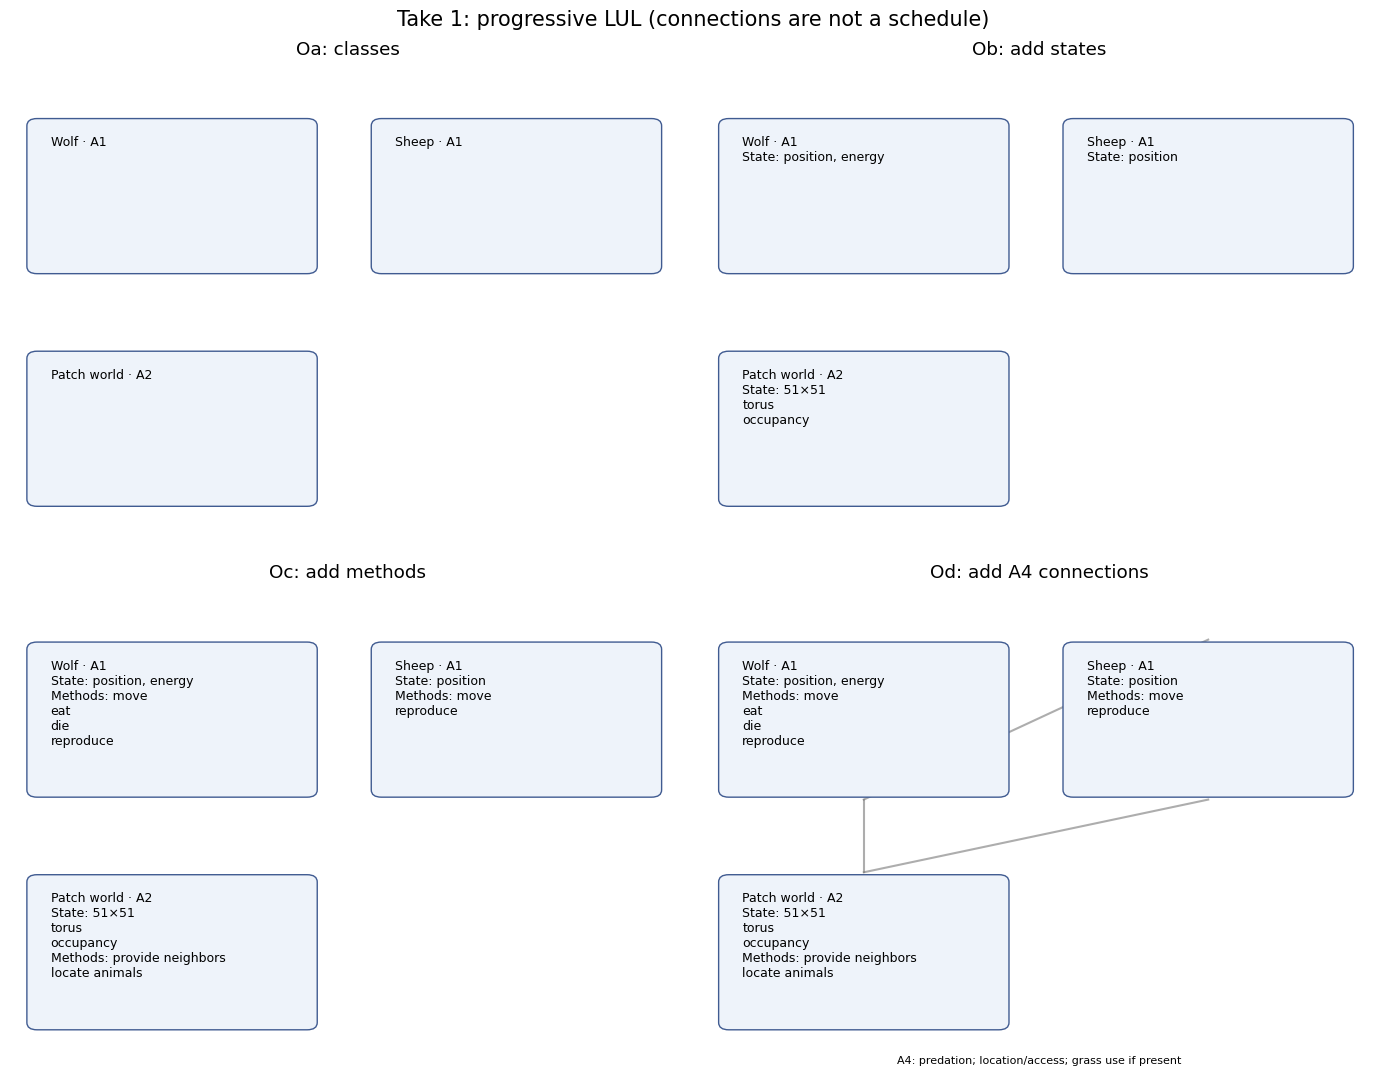

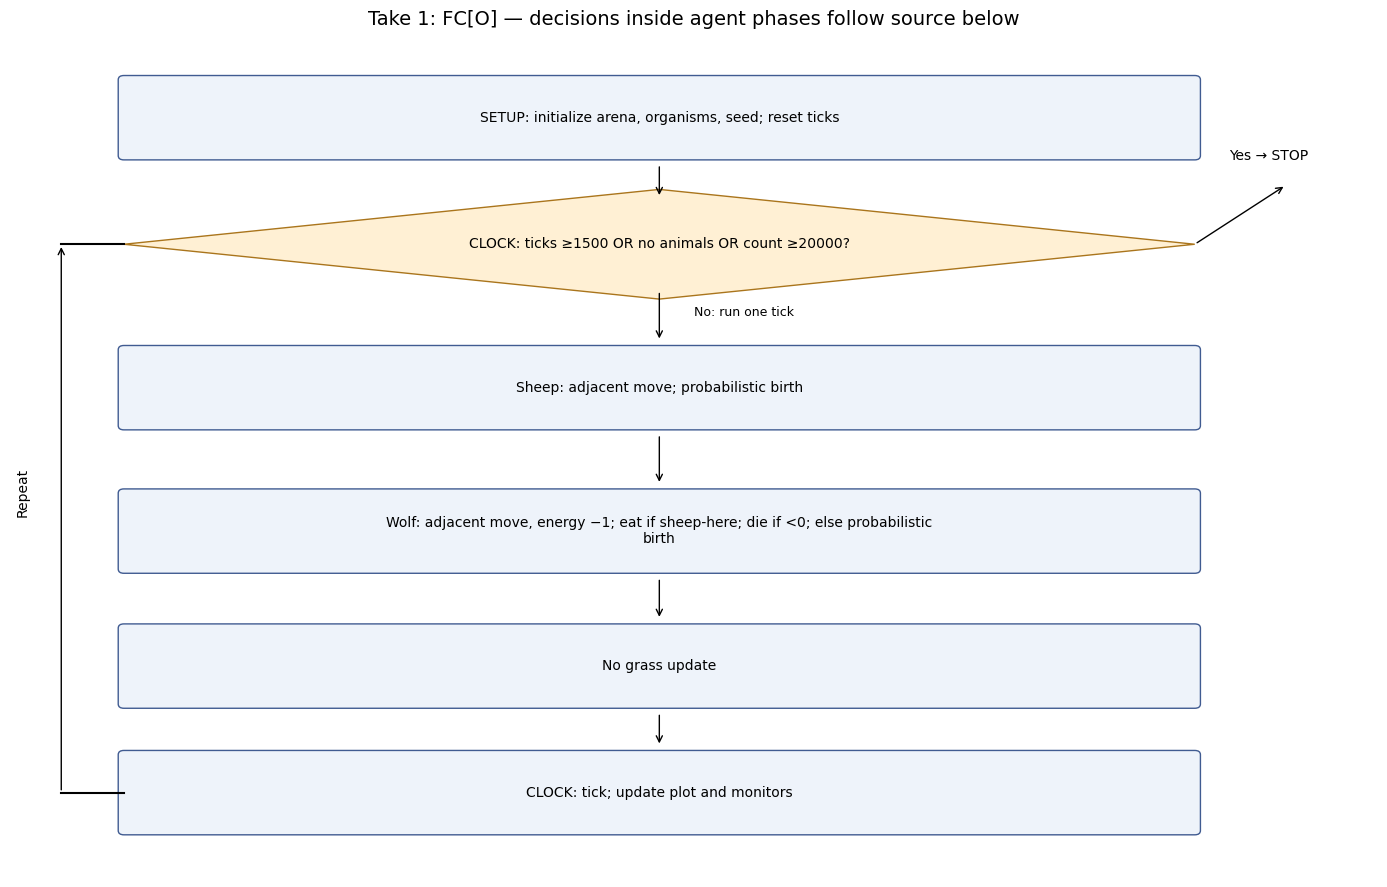

In [5]:
lul(1)
flow(1)

**Reading the LUL stages:** Oa selects only classes and roles; Ob states what must be stored; Oc declares capabilities; Od enables access among instances. For occupancy, additionally read Sheep–Sheep and Wolf–Wolf access through the Arena. Neither these connections nor a named method executes anything: the source and schedule define its effect.

**Actual runnable source:** the following cell displays the entire code used in the exported model, including initialization, agent branches, and reporters.

In [9]:
show_source(1)

```netlogo
; Session 5 teaching reconstruction of Wilensky & Reisman rule summaries.
; Implementation choices are documented in the notebook.
globals [ take-number sheep-gain-from-food wolf-gain-from-food
          move-cost seed-value max-ticks population-cap stop-reason ]
breed [ sheep a-sheep ]
breed [ wolves wolf ]
turtles-own [ energy ]
patches-own [ countdown ]

to setup
  clear-all
  set take-number 1
  set seed-value 2026
  random-seed seed-value
  set sheep-gain-from-food 4
  set wolf-gain-from-food 20
  set move-cost 1
  set max-ticks 1500
  set population-cap 20000
  set stop-reason "running"
  ask patches [ set pcolor brown set countdown 0 ]
  if take-number = 2 [
    ask n-of (floor (count patches / 2)) patches [ set pcolor green ]
    ask patches with [pcolor = brown] [
      set countdown random (max (list 1 grass-regrowth-time))
    ]
  ]
  if take-number = 3 [
    if initial-number-sheep > count patches or initial-number-wolves > count patches [
      error "Each initial species must fit into the patch world."
    ]
  ]
  create-sheep initial-number-sheep [
    set shape "sheep" set color white set size 1
    set energy random sheep-gain-from-food
    ifelse take-number = 3
      [ move-to one-of patches with [not any? sheep-here] ]
      [ move-to one-of patches ]
  ]
  create-wolves initial-number-wolves [
    set shape "wolf" set color black set size 1.3
    set energy random wolf-gain-from-food
    ifelse take-number = 3
      [ move-to one-of patches with [not any? wolves-here] ]
      [ move-to one-of patches ]
  ]
  reset-ticks
end

to go
  if ticks >= max-ticks [ set stop-reason "time limit" stop ]
  if not any? turtles [ set stop-reason "no animals" stop ]
  if count turtles >= population-cap [ set stop-reason "population safety cap" stop ]
  ; ask uses a random order within each breed; sheep act before wolves.
  ask sheep [ sheep-step ]
  ask wolves [ wolf-step ]
  if take-number = 2 [ ask patches [ grow-grass ] ]
  tick
end

to sheep-step
  ifelse take-number = 3
    [ let target one-of neighbors with [not any? sheep-here]
      if target != nobody [ move-to target ] ]
    [ move-to one-of neighbors ]
  if take-number = 2 [
    set energy energy - move-cost
    if pcolor = green [
      set pcolor brown
      set countdown grass-regrowth-time
      set energy energy + sheep-gain-from-food
    ]
    if energy < 0 [ die ]
  ]
  if random-float 100 < sheep-reproduce [
    ifelse take-number = 3
      [ let target one-of neighbors with [not any? turtles-here]
        if target != nobody [ hatch 1 [ move-to target ] ] ]
      [ if take-number = 2 [ set energy energy / 2 ]
        hatch 1 [ move-to one-of neighbors ] ]
  ]
end

to wolf-step
  ifelse take-number = 3
    [ let target one-of neighbors with [not any? wolves-here]
      if target != nobody [ move-to target ] ]
    [ move-to one-of neighbors ]
  ; Energy costs apply even if a crowded wolf cannot move (W2 step 2).
  set energy energy - move-cost
  let prey one-of sheep-here
  if prey != nobody [ ask prey [ die ] set energy energy + wolf-gain-from-food ]
  if energy < 0 [ die ]
  if random-float 100 < wolf-reproduce [
    ifelse take-number = 3
      [ let target one-of neighbors with [not any? wolves-here]
        if target != nobody [
          set energy energy / 2
          hatch 1 [ move-to target ]
        ] ]
      [ set energy energy / 2
        hatch 1 [ move-to one-of neighbors ] ]
  ]
end

to grow-grass
  if pcolor = brown [
    set countdown countdown - 1
    if countdown <= 0 [ set pcolor green ]
  ]
end

to-report land_with_grass
  if take-number != 2 [ report 0 ]
  report 100 * count patches with [pcolor = green] / count patches
end

to-report occupancy-ok?
  report not any? patches with [count sheep-here > 1 or count wolves-here > 1]
end

```

**Student exercise 3:** Run seeds 2026, 2027, and 2028 at the same sliders. Record the last tick, whether each species survives, and whether the safety cap was reached. Explain why extinction is absorbing here. Propose a mechanism that limits prey growth, and trace changes to LUL states, methods, connections, and the CLOCK process before coding it.

**Observation record (complete after running NetLogo):** take / slider settings / seed / last tick / sheep / wolves / grass % if applicable / reason stopped / observation / interpretation. A blank record is not a computed result.

## 5 · Take 2: W1 + S2 + P1 · renewable grass

**Paper mapping:** S2/P1 on p. 23; Figure 4 on p. 24. Wolves retain W1. Sheep now spend energy, consume local grass, and can starve. Brown patches regenerate after a waiting time. Sheep can still share a patch; grass is depleted locally, one grazing event at a time.

**Ontology revision:** Grass A3m states and regrowth capability; Sheep energy and grazing/starvation methods; Sheep–Grass and Grass–Arena access. Grass resides in patch attributes and colors; there are no grass turtles.

**Paper-reported expectation:** coexistence with fluctuating grass under appropriate settings. Stable here means persistence over the observed horizon, not constant populations or a universal theorem. Predator/grass fluctuations can be roughly opposite to sheep. Record actual outputs instead of labeling every grass run “stable.”

**Timing convention:** consuming grass assigns countdown X, then the patch phase decrements it during that tick. For integer X≥1, it becomes green in the Xth patch update including that tick. The instructor’s existing code tests the clock before decrementing and resets it at regrowth rather than consumption. Therefore this reconstruction is not a byte-for-byte replication of existing CSV-generating code.

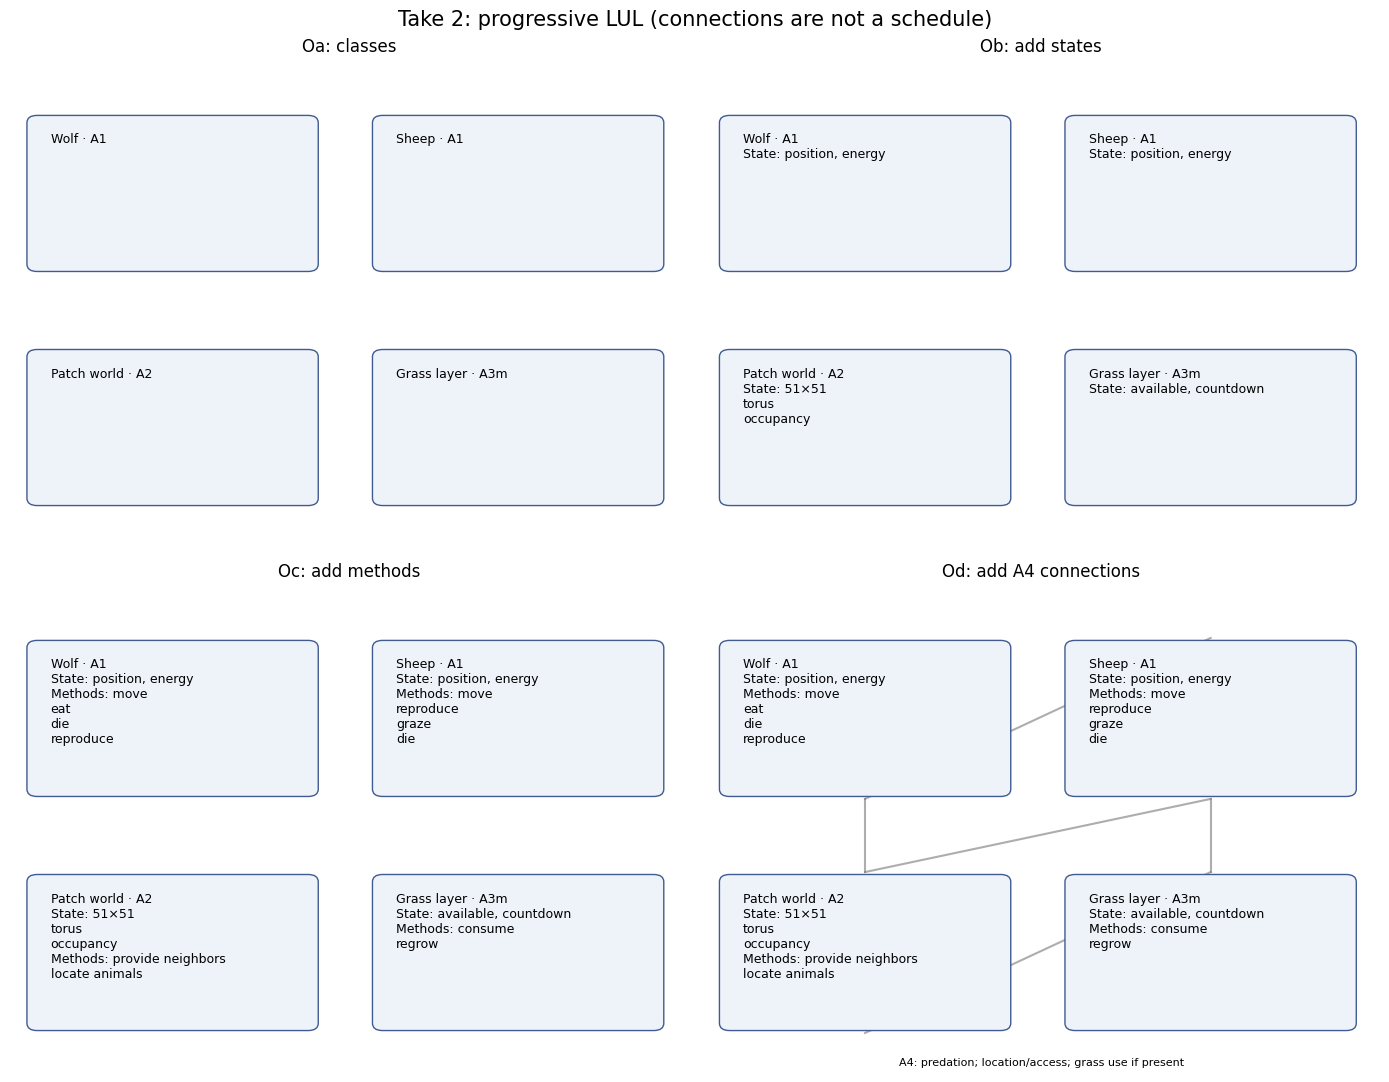

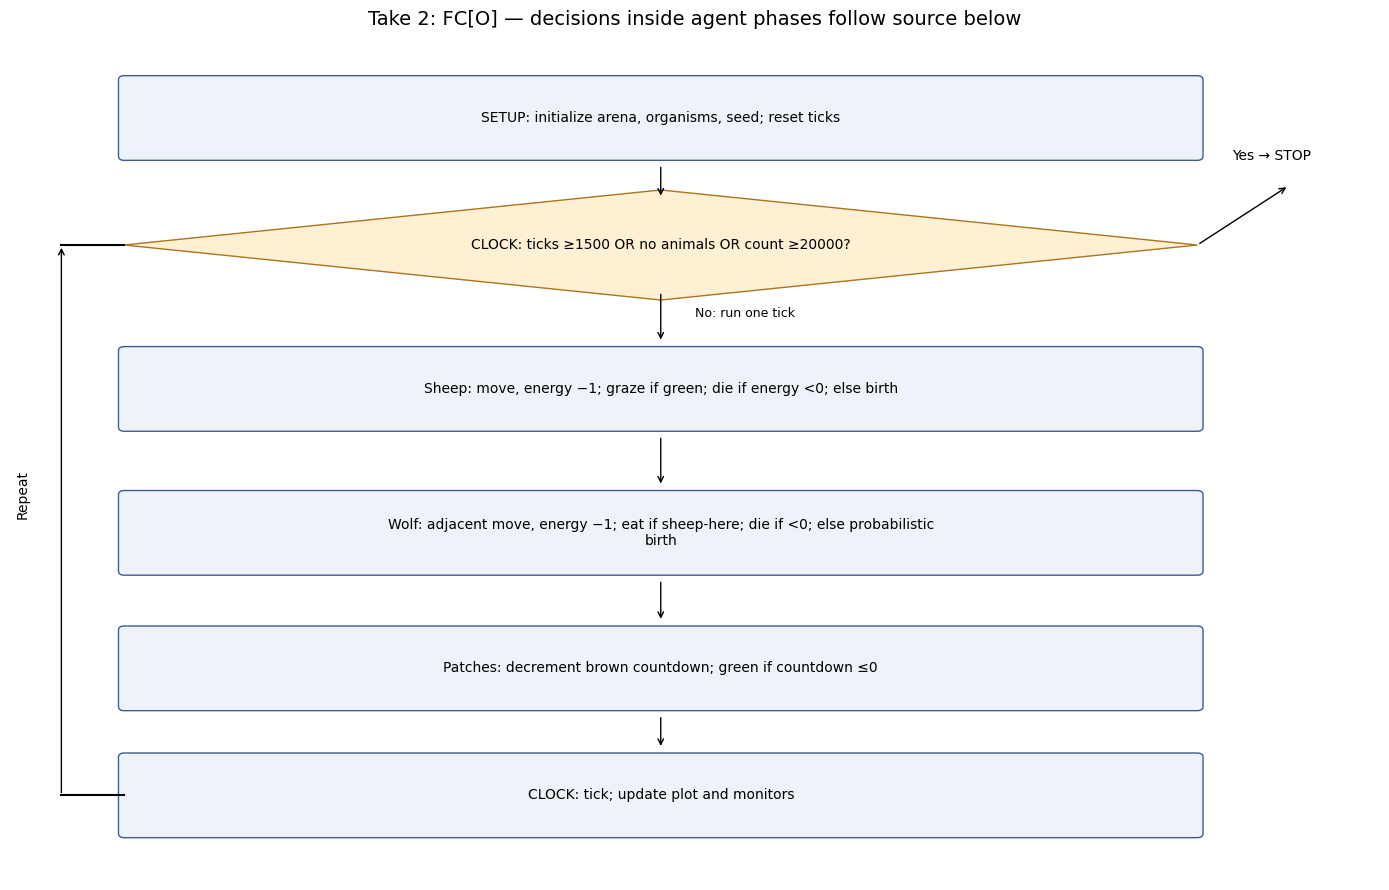

In [10]:
lul(2)
flow(2)

**Reading the LUL stages:** Oa selects only classes and roles; Ob states what must be stored; Oc declares capabilities; Od enables access among instances. For occupancy, additionally read Sheep–Sheep and Wolf–Wolf access through the Arena. Neither these connections nor a named method executes anything: the source and schedule define its effect.

**Actual runnable source:** the following cell displays the entire code used in the exported model, including initialization, agent branches, and reporters.

In [11]:
show_source(2)

```netlogo
; Session 5 teaching reconstruction of Wilensky & Reisman rule summaries.
; Implementation choices are documented in the notebook.
globals [ take-number sheep-gain-from-food wolf-gain-from-food
          move-cost seed-value max-ticks population-cap stop-reason ]
breed [ sheep a-sheep ]
breed [ wolves wolf ]
turtles-own [ energy ]
patches-own [ countdown ]

to setup
  clear-all
  set take-number 2
  set seed-value 2026
  random-seed seed-value
  set sheep-gain-from-food 4
  set wolf-gain-from-food 20
  set move-cost 1
  set max-ticks 1500
  set population-cap 20000
  set stop-reason "running"
  ask patches [ set pcolor brown set countdown 0 ]
  if take-number = 2 [
    ask n-of (floor (count patches / 2)) patches [ set pcolor green ]
    ask patches with [pcolor = brown] [
      set countdown random (max (list 1 grass-regrowth-time))
    ]
  ]
  if take-number = 3 [
    if initial-number-sheep > count patches or initial-number-wolves > count patches [
      error "Each initial species must fit into the patch world."
    ]
  ]
  create-sheep initial-number-sheep [
    set shape "sheep" set color white set size 1
    set energy random sheep-gain-from-food
    ifelse take-number = 3
      [ move-to one-of patches with [not any? sheep-here] ]
      [ move-to one-of patches ]
  ]
  create-wolves initial-number-wolves [
    set shape "wolf" set color black set size 1.3
    set energy random wolf-gain-from-food
    ifelse take-number = 3
      [ move-to one-of patches with [not any? wolves-here] ]
      [ move-to one-of patches ]
  ]
  reset-ticks
end

to go
  if ticks >= max-ticks [ set stop-reason "time limit" stop ]
  if not any? turtles [ set stop-reason "no animals" stop ]
  if count turtles >= population-cap [ set stop-reason "population safety cap" stop ]
  ; ask uses a random order within each breed; sheep act before wolves.
  ask sheep [ sheep-step ]
  ask wolves [ wolf-step ]
  if take-number = 2 [ ask patches [ grow-grass ] ]
  tick
end

to sheep-step
  ifelse take-number = 3
    [ let target one-of neighbors with [not any? sheep-here]
      if target != nobody [ move-to target ] ]
    [ move-to one-of neighbors ]
  if take-number = 2 [
    set energy energy - move-cost
    if pcolor = green [
      set pcolor brown
      set countdown grass-regrowth-time
      set energy energy + sheep-gain-from-food
    ]
    if energy < 0 [ die ]
  ]
  if random-float 100 < sheep-reproduce [
    ifelse take-number = 3
      [ let target one-of neighbors with [not any? turtles-here]
        if target != nobody [ hatch 1 [ move-to target ] ] ]
      [ if take-number = 2 [ set energy energy / 2 ]
        hatch 1 [ move-to one-of neighbors ] ]
  ]
end

to wolf-step
  ifelse take-number = 3
    [ let target one-of neighbors with [not any? wolves-here]
      if target != nobody [ move-to target ] ]
    [ move-to one-of neighbors ]
  ; Energy costs apply even if a crowded wolf cannot move (W2 step 2).
  set energy energy - move-cost
  let prey one-of sheep-here
  if prey != nobody [ ask prey [ die ] set energy energy + wolf-gain-from-food ]
  if energy < 0 [ die ]
  if random-float 100 < wolf-reproduce [
    ifelse take-number = 3
      [ let target one-of neighbors with [not any? wolves-here]
        if target != nobody [
          set energy energy / 2
          hatch 1 [ move-to target ]
        ] ]
      [ set energy energy / 2
        hatch 1 [ move-to one-of neighbors ] ]
  ]
end

to grow-grass
  if pcolor = brown [
    set countdown countdown - 1
    if countdown <= 0 [ set pcolor green ]
  ]
end

to-report land_with_grass
  if take-number != 2 [ report 0 ]
  report 100 * count patches with [pcolor = green] / count patches
end

to-report occupancy-ok?
  report not any? patches with [count sheep-here > 1 or count wolves-here > 1]
end

```

**Student exercise 4:** Predict what slowing regrowth does before changing the slider. Run at least three seeds with one parameter changed. Separate mechanistic reasoning from a single trajectory. Compare the displayed source with the original exported teaching model: identify differences in movement, regrowth, and newborn placement. Why should existing CSVs be analyzed using their original model, not this reconstruction?

**Observation record (complete after running NetLogo):** take / slider settings / seed / last tick / sheep / wolves / grass % if applicable / reason stopped / observation / interpretation. A blank record is not a computed result.

## 6 · Take 3: W2 + S3 · occupancy without grass

**Paper mapping:** S3 on p. 25, W2 on p. 26, interpretation pp. 26–27. Grass and sheep starvation are removed. Sheep move only to sheep-free adjacent patches; wolves move only to wolf-free adjacent patches. If blocked, they stay. Wolf energy falls even when movement is blocked. A sheep and a wolf may occupy the same patch, enabling predation.

**Explicit resolution of summary ambiguities:** S3 says offspring go into an “unoccupied” adjacent patch: here it means **no animals of either breed**, while sheep movement needs only no sheep. W2 lists probabilistic birth but does not specify placement. Here wolf birth additionally requires a wolf-free adjacent patch, preserving the prose’s limit of one animal per species per patch. That extra placement guard is an implementation completion; do not claim it was explicit in W2 step 5. Test these choices as alternatives.

**Ontology revision:** remove Grass and sheep energy; make local occupancy queryable through the Arena; birth methods require a target patch. Same-class access (Sheep–Sheep and Wolf–Wolf, mediated through patch queries) constrains space; Wolf–Sheep access still supports predation.

**Paper-reported expectation:** occupancy alone initially remained unstable; higher birth rates yielded persistent oscillations in the explored cases. Compared with grass, these were more regular, larger in amplitude, and spatially clustered. Defaults of 40%/40% are illustrative, not recovered paper parameters, and no indefinite persistence claim follows from a finite run.

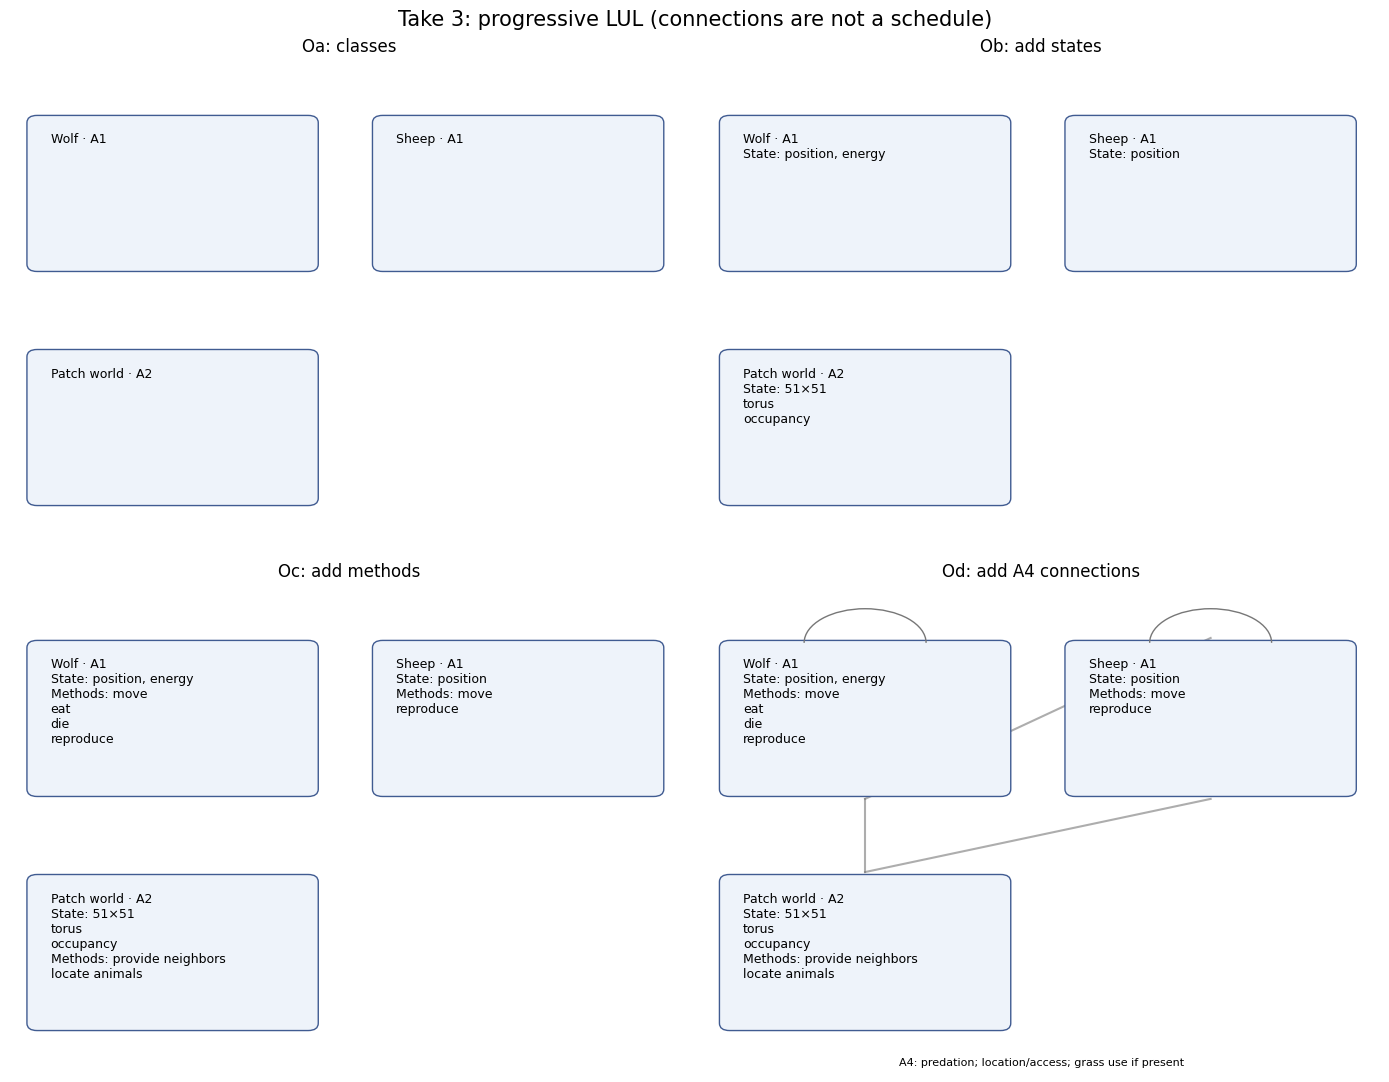

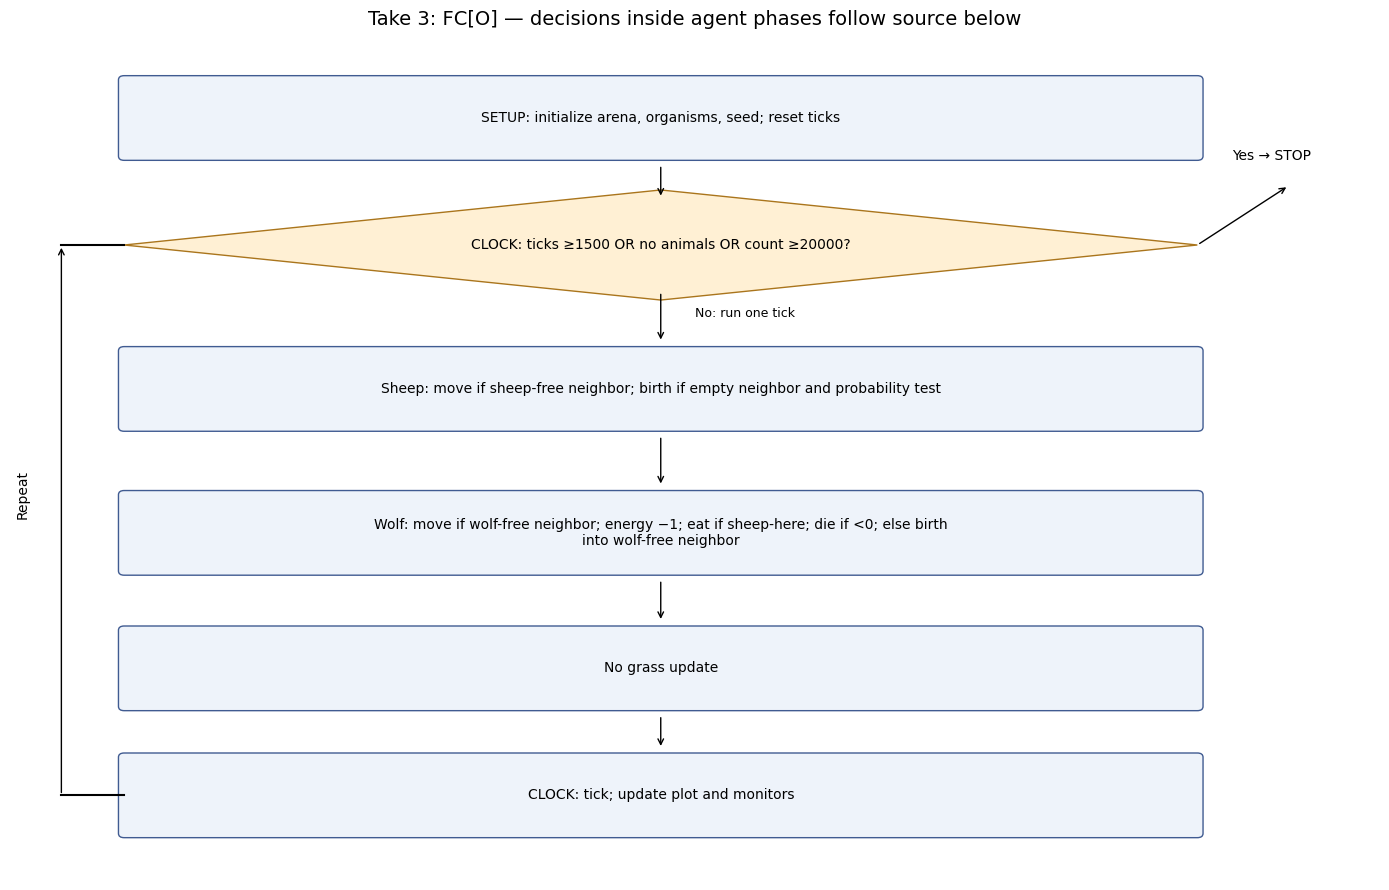

In [12]:
lul(3)
flow(3)

**Reading the LUL stages:** Oa selects only classes and roles; Ob states what must be stored; Oc declares capabilities; Od enables access among instances. For occupancy, additionally read Sheep–Sheep and Wolf–Wolf access through the Arena. Neither these connections nor a named method executes anything: the source and schedule define its effect.

**Actual runnable source:** the following cell displays the entire code used in the exported model, including initialization, agent branches, and reporters.

In [13]:
show_source(3)

```netlogo
; Session 5 teaching reconstruction of Wilensky & Reisman rule summaries.
; Implementation choices are documented in the notebook.
globals [ take-number sheep-gain-from-food wolf-gain-from-food
          move-cost seed-value max-ticks population-cap stop-reason ]
breed [ sheep a-sheep ]
breed [ wolves wolf ]
turtles-own [ energy ]
patches-own [ countdown ]

to setup
  clear-all
  set take-number 3
  set seed-value 2026
  random-seed seed-value
  set sheep-gain-from-food 4
  set wolf-gain-from-food 20
  set move-cost 1
  set max-ticks 1500
  set population-cap 20000
  set stop-reason "running"
  ask patches [ set pcolor brown set countdown 0 ]
  if take-number = 2 [
    ask n-of (floor (count patches / 2)) patches [ set pcolor green ]
    ask patches with [pcolor = brown] [
      set countdown random (max (list 1 grass-regrowth-time))
    ]
  ]
  if take-number = 3 [
    if initial-number-sheep > count patches or initial-number-wolves > count patches [
      error "Each initial species must fit into the patch world."
    ]
  ]
  create-sheep initial-number-sheep [
    set shape "sheep" set color white set size 1
    set energy random sheep-gain-from-food
    ifelse take-number = 3
      [ move-to one-of patches with [not any? sheep-here] ]
      [ move-to one-of patches ]
  ]
  create-wolves initial-number-wolves [
    set shape "wolf" set color black set size 1.3
    set energy random wolf-gain-from-food
    ifelse take-number = 3
      [ move-to one-of patches with [not any? wolves-here] ]
      [ move-to one-of patches ]
  ]
  reset-ticks
end

to go
  if ticks >= max-ticks [ set stop-reason "time limit" stop ]
  if not any? turtles [ set stop-reason "no animals" stop ]
  if count turtles >= population-cap [ set stop-reason "population safety cap" stop ]
  ; ask uses a random order within each breed; sheep act before wolves.
  ask sheep [ sheep-step ]
  ask wolves [ wolf-step ]
  if take-number = 2 [ ask patches [ grow-grass ] ]
  tick
end

to sheep-step
  ifelse take-number = 3
    [ let target one-of neighbors with [not any? sheep-here]
      if target != nobody [ move-to target ] ]
    [ move-to one-of neighbors ]
  if take-number = 2 [
    set energy energy - move-cost
    if pcolor = green [
      set pcolor brown
      set countdown grass-regrowth-time
      set energy energy + sheep-gain-from-food
    ]
    if energy < 0 [ die ]
  ]
  if random-float 100 < sheep-reproduce [
    ifelse take-number = 3
      [ let target one-of neighbors with [not any? turtles-here]
        if target != nobody [ hatch 1 [ move-to target ] ] ]
      [ if take-number = 2 [ set energy energy / 2 ]
        hatch 1 [ move-to one-of neighbors ] ]
  ]
end

to wolf-step
  ifelse take-number = 3
    [ let target one-of neighbors with [not any? wolves-here]
      if target != nobody [ move-to target ] ]
    [ move-to one-of neighbors ]
  ; Energy costs apply even if a crowded wolf cannot move (W2 step 2).
  set energy energy - move-cost
  let prey one-of sheep-here
  if prey != nobody [ ask prey [ die ] set energy energy + wolf-gain-from-food ]
  if energy < 0 [ die ]
  if random-float 100 < wolf-reproduce [
    ifelse take-number = 3
      [ let target one-of neighbors with [not any? wolves-here]
        if target != nobody [
          set energy energy / 2
          hatch 1 [ move-to target ]
        ] ]
      [ set energy energy / 2
        hatch 1 [ move-to one-of neighbors ] ]
  ]
end

to grow-grass
  if pcolor = brown [
    set countdown countdown - 1
    if countdown <= 0 [ set pcolor green ]
  ]
end

to-report land_with_grass
  if take-number != 2 [ report 0 ]
  report 100 * count patches with [pcolor = green] / count patches
end

to-report occupancy-ok?
  report not any? patches with [count sheep-here > 1 or count wolves-here > 1]
end

```

**Student exercise 5:** Compare 4%/5% births with 40%/40% births using three seeds each. Check occupancy after a run by typing `show occupancy-ok?` in the Command Center. Explain why `not any? turtles-here` would be wrong for wolf movement if it prevented encounters with prey. WHAT IS: add sheep energy or a shelter layer. HOW: reverse breed order or change wolf newborn placement. For each change trace states, methods, A4 access, flow, and expected measurements.

**Observation record (complete after running NetLogo):** take / slider settings / seed / last tick / sheep / wolves / grass % if applicable / reason stopped / observation / interpretation. A blank record is not a computed result.

## 7 · Compare explanations, not just curves
| Dimension | Lotka–Volterra | W1 + S1 | Grass | Occupancy |
|---|---|---|---|---|
| Representation | Continuous populations | Discrete animals, local encounters | Animals plus renewable resource | Animals plus spatial restrictions |
| Prey growth limit | None intrinsic | None intrinsic | Feeding and starvation | Available sites for birth |
| Predator recruitment | Interaction term | Probabilistic birth, energy survival | Same as W1 | Birth probability plus placement choice |
| Space | Implicit mixing | Explicit patches | Explicit local grazing | Explicit crowding |
| Stochasticity | None | Movement, order, births | Same plus resource initialization | Same, constrained targets |
| Extinction | No integer threshold | Possible | Possible | Possible |
| Evidence here | SciPy computed curve | Run NetLogo to obtain | Run NetLogo to obtain | Run NetLogo to obtain |

Similar oscillations can arise from different mechanisms. Neither matching a curve nor adding realistic detail proves a mechanism is correct. Compare micro-level assumptions, spatial arrangements, time series, and independent observations. The paper discusses the danger of curve fitting (pp. 18–19) and contrasting model explanations (pp. 27–28).

**Exercise 6:** Choose two takes that oscillate in your runs. Identify two observations beyond the population curve that could discriminate them. Explain why an ODE coefficient cannot be copied into an ABM slider without a mapping of units, scale, and encounter processes.

### Fidelity ledger
| Topic | Verified source | Treatment here |
|---|---|---|
| Empirical pattern and classical equations | Paper Fig. 1, pp. 11–13 | Actual figure; exact equation form; new illustrative parameters |
| First rules and failures | W1/S1 p. 15; Fig. 3 p. 17 | Adjacent movement, co-location, energy <0, probability birth |
| Grass | S2/P1 p. 23; Fig. 4 p. 24 | Local resource and clock; explicit update convention |
| Occupancy | S3 p. 25; W2 p. 26; discussion p. 27 | Breed-specific movement; sheep birth into fully empty site; guarded wolf birth |
| Reproduction notation | S1 uses R2; S2/S3 print R1, also used for wolves | Separate sheep/wolf sliders; notation inconsistency disclosed |
| Code vs summaries | Instructor `.nlogox` | Energy sharing and modular procedures retained; movement and grass timing changed |
| Four As / LUL | Homework2.pdf, pp. 1, 3–5 | Exact category names; progressive diagrams; A4 distinct from flow |
| Experimental design | Instructor model Info + experiments; ABMS_5 deck | Original design below, kept separate from classroom reconstructions |

The code is a documented reconstruction of published summary rules, not a recovered historical implementation or a numerical replication of every paper figure.


## 8 · BehaviorSpace: from a run to an experiment
Use **desktop NetLogo**, Tools → BehaviorSpace. NetLogo Web is for classroom exploration; it does not replace desktop BehaviorSpace. The exported **instructor_original.nlogox** retains the supplied source and the two original experiment definitions. Open it to reproduce the instructor’s experiment; do not substitute a reconstructed take for analysis of existing results.

| Design element | Original course design |
|---|---|
| Initial populations | Separate experiments: 100 sheep/100 wolves; 400 sheep/400 wolves |
| Sheep reproduction | 4 to 20, step 2 (9 values) |
| Wolf reproduction | 4 to 20, step 2 (9 values) |
| Grass regrowth time | 150 to 250, step 25 (5 values) |
| Repetitions | 3 per combination |
| Go command | `go` |
| Metrics | `land_with_grass`, `count sheep`, `count wolves` |
| Run metrics every step | Off: final values only |
| Exit condition | `(land_with_grass = 0) or (not any? turtles)` |
| Time limit | 1,500 ticks |

**Important:** `not any? turtles` means **both species absent**, not extinction of either one. Zero grass triggers stopping even though grass could later regenerate; it is not proof of irreversible ecological collapse. Endpoints can arise from different stop reasons and run lengths. Final-value exports cannot establish oscillation amplitude or phase lag.

The original model has initial-population sliders limited to 20 and grass-regrowth slider limited to 200, while experiment commands set populations to 100/400 and vary regrowth up to 250. The experiment definitions deliberately set these values directly; classroom slider ranges do not describe the experimental grid. The original preview commands also refer to removed variables; use the setup button rather than preview generation.

For a **new** experiment, pre-register horizon and metrics, record seed and ticks, and distinguish time-limit, zero-grass, and no-animal exits. Do not retroactively change the design of the existing CSVs. Three repetitions demonstrate stochastic variation but give limited precision. Keep scenario world size fixed: quadrupling initial numbers quadruples density, so this is not a pure scale comparison.


In [14]:
from itertools import product
parameter_grid = list(product(range(4, 21, 2), range(4, 21, 2), range(150, 251, 25)))
print('Combinations per scenario:', len(parameter_grid))
print('Runs per scenario:', len(parameter_grid) * 3)
print('Total runs:', len(parameter_grid) * 3 * 2)
assert len(parameter_grid) == 405
# Design arithmetic only. No CSVs are loaded or analyzed in this session.


Combinations per scenario: 405
Runs per scenario: 1215
Total runs: 2430


### Classroom demonstration and student design exercise
Use a small new experiment first: one population scenario, sheep birth 4/8, wolf birth 4/8, regrowth 200, three repetitions, 50 ticks. Name it separately from the original experiments. Inspect how settings, stop condition, reporters, and repetitions differ from pressing go once. Repeated setups in the reconstruction reset the seed, so a new reconstruction experiment must assign distinct seeds **after setup**; the original model does not hard-code a seed.

**Exercise 7:** State a hypothesis about the 100/100 versus 400/400 scenarios; identify initial conditions, behavioral parameters, outcomes, and confounders. Predict what the zero-grass exit does to comparisons. Propose two ontological WHAT IS and two procedural HOW changes, tracing each through several parts of LUL and FC. Judge added complexity using KISS.

### Stop here: analysis after Homework 2
The instructor will provide the completed CSV results. The later session will audit export headers, design provenance, terminal conditions, and comparable outcomes before estimating differences. This notebook intentionally includes **no existing CSV analysis** and does not impose a social-process outcome on Homework 2, which remains an ex-ante ontology/flowchart assignment.

## 9 · Sources and reproducibility
Primary teaching sources actually inspected:
- Wilensky, U. & Reisman, K. (2006), *Thinking like a Wolf, a Sheep or a Firefly: Learning Biology through Constructing and Testing Computational Theories—an Embodied Modeling Approach*, uploaded `wolfsheep.pdf`. Page references above use the uploaded manuscript pagination, not journal pages 171–209. [Author-hosted paper](https://ccl.northwestern.edu/papers/wolfsheep.pdf).
- User’s `Homework2.pdf`: Four As, progressive LUL, explicit CLOCK, diagnosis, WHAT IF, and parsimony.
- User’s `7_Wolf_Sheep_Predation_simpler.nlogox`: modular procedures, energetic births, grass initialization, reporters, model credits, and embedded experimental definitions. Its original source is exported unchanged for provenance.
- `ABMS_5_dacss.pptx`: setup → common/sheep/wolf/patch procedures → reporters → BehaviorSpace → later outside-NetLogo analysis. This notebook turns that teaching progression into an interactive laboratory.
- Earlier referenced modules cover setup, agents, execution controls, interface, results, and subroutines; the bridge in this notebook follows those topics. No claim is made to have inspected every earlier module.
- [NetLogo Web FAQ](https://www.netlogoweb.org/docs/faq) and [Hosting and Sharing](https://netlogo-web.org/docs/hosting-sharing), checked during preparation.

**Attribution:** NetLogo Wolf Sheep Predation, Uri Wilensky (1997), Center for Connected Learning and Computer-Based Modeling, Northwestern University; teaching adaptation by Jose Manuel Magallanes. Exported derived model files use the original **CC BY-NC-SA 3.0** terms. Historical Figure 1 is reproduced from the supplied paper with its original attribution; it is not newly generated data.

**Verification:** Python and NetLogo verification results are recorded below after preparation. Browser interaction and widget availability depend on the receiving front end. Finite smoke runs check executability and invariants; they do not establish ecological validity or indefinite coexistence.


### Preparation verification (computed checks)
All three reconstructed `.nlogox` files compiled and ran 50 ticks in NetLogo 7.0.3, seed 2026, defaults as exported. These are short executability checks, not figure replications:

| Take | Tick | Sheep | Wolves | Grass % | Occupancy invariant |
|---|---:|---:|---:|---:|---|
| W1 + S1 | 50 | 280 | 41 | N/A | N/A (unrestricted) |
| Grass | 50 | 147 | 8 | 56.25 | N/A (unrestricted) |
| Occupancy | 50 | 0 | 503 | N/A | True at every recorded tick |

The occupancy default loses its sheep in this run—an instructive outcome, not stable coexistence. Higher reproduction alone is not sufficient in every implementation/parameter configuration. Explore food gains, energy-sharing, world density, and seed as explicit hypotheses rather than hiding this result. Occupancy remains one animal of each species per patch.

Python cells were executed sequentially during preparation; the stored SciPy plots and diagrams are their outputs. Widget controls require a supporting notebook front end. NetLogo Web launch/upload guidance follows official documentation; the exported models were verified on desktop, not through a browser compatibility test. The existing instructor model is preserved unchanged and its full experiments were not rerun.
